# EDA, desbalance y contraste A vs AB sobre el test gold

Notebook autocontenido para una pista de etiquetas. El 08 corre la pista **M** y el 09 la pista **S**; los dos tienen las mismas
celdas y solo difieren en `PISTA`, dentro de la celda de configuración.

| Pista | Entrenamiento | Objetivo | Validación (V) |
|---|---|---|---|
| M | `natural.csv` | KD: distribución del QLoRA (`dist[:9]` renormalizada) en filas `qlora`; one-hot en filas `haiku` | `validacion.csv` |
| S | `sonnet.csv` | etiqueta dura de Sonnet | `validacion_sonnet.csv` |

**Reglas.**
- El test gold no participa en ninguna decisión. Hasta la sección 6 solo se leen sus `context_id`, para los controles de fuga.
- Toda selección (estrategia de desbalance, lr, ajuste post-hoc) se hace sobre V.
- El dev (15 % de train, separado por citante) sirve para el early stopping y para ajustar los sesgos post-hoc.
- A y AB usan exactamente las mismas citas e hiperparámetros. AB usa el fragmentador **V2**, que divide los párrafos largos sin
  truncar. Con eso la cobertura de AB pasa de ~55 % (V1) a ~99 %.
- Sin imports de `packages/` ni de `proyecto_de_grado/src`: todo se reimplementa aquí.

**Secciones.** 0 Configuración · 1 Datos y controles de fuga · 2 Fragmentación V2, Top-3 y entradas · 3 EDA ·
4 Modelo y entrenamiento · 5 Experimentos (fases 1–3) · 6 Evaluación en el test gold.

In [1]:
import gc
import hashlib
import json
import math
import os
import platform
import random
import re
import time
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch
import transformers
from scipy import stats
from sklearn.metrics import cohen_kappa_score
from torch import nn
from torch.utils.data import DataLoader, WeightedRandomSampler
from transformers import AutoModel, AutoTokenizer, get_linear_schedule_with_warmup

/home/carlos/microproyecto-local-citation/local_workflows/.venv-qlora/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0. Configuración

Todo lo que cambia entre pistas está en esta celda. `MODO_PRUEBA = True` hace una corrida corta de punta a punta:
- submuestras de train, dev, V y gold;
- 1 época y 2 semillas;
- todas las estrategias en la fase 1 y una sola corrida en la fase 2;
- salidas en `experimentos_08_09_prueba`.

La caché de embeddings de chunks es la misma en los dos modos.

In [2]:
PISTA = "S"            # "M" (notebook 08) | "S" (notebook 09)
MODO_PRUEBA = False    # True: corrida corta de verificacion (submuestras, 1 epoca, 2 semillas)

PISTAS = {
    "M": {"train": "natural.csv", "v": "validacion.csv", "kd": True, "otra_train": "sonnet.csv", "otra_v": "validacion_sonnet.csv"},
    "S": {"train": "sonnet.csv", "v": "validacion_sonnet.csv", "kd": False, "otra_train": "natural.csv", "otra_v": "validacion.csv"},
}
CFG = PISTAS[PISTA]

# ---- rutas (solo datos)
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS = REPO / "proyecto_de_grado/artifacts/experimentos_104/datos"
RAW = REPO / "data/raw"
CACHE_OCL = REPO / "proyecto_de_grado/scripts/spike_enlace_datos/cache_ocl"
PREDS_QLORA = [REPO / "local_workflows/qlora_18000_preds_v2.jsonl",
               *[REPO / f"local_workflows/subconjuntos_qlora/CITAS_NO_USADAS_0{i}_qlora_v2_preds.jsonl" for i in range(1, 6)]]
CONFIANZA_SONNET = REPO / "proyecto_de_grado/anotacion/sonnet/etiquetas_sonnet.csv"
GOLD_CSV = REPO / "proyecto_de_grado/anotacion/test_gold_final/test_gold_final.csv"
GOLD_SHA_PREFIJO = "80e4d9a6"
TOP3_REFERENCIA = REPO / "proyecto_de_grado/docs/evidencias_experimentos_104_b_v2/top3_gold_v2.csv"
REF_104 = {"M": "scibert-A-natural-kd-lr3e-05-e4", "S": "scibert-S-sonnet-lr3e-05-e4"}[PISTA]
DIR_REF_104 = REPO / "proyecto_de_grado/artifacts/test_gold"
HF_HOME = Path(os.environ.get("HF_HOME", Path.home() / ".cache/huggingface"))
SCIBERT = HF_HOME / "hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1"

SUFIJO = "_prueba" if MODO_PRUEBA else ""
ARTIFACTS = REPO / f"proyecto_de_grado/artifacts/experimentos_08_09{SUFIJO}"
SALIDA = ARTIFACTS / PISTA
CORRIDAS = SALIDA / "corridas"
CACHE_CHUNKS = REPO / "proyecto_de_grado/artifacts/experimentos_08_09/cache_chunks"   # compartida por 08, 09 y la prueba
EVIDENCIAS = SALIDA / "evidencias" if MODO_PRUEBA else REPO / "proyecto_de_grado/docs/evidencias_experimentos_08_09"
for carpeta in (CORRIDAS, CACHE_CHUNKS, EVIDENCIAS):
    carpeta.mkdir(parents=True, exist_ok=True)

# ---- taxonomia
CLASES = ("Background", "Gap", "Basis", "Comparison", "Application", "Improvement / Modification", "Evidence",
          "Identification of the Originator", "Further Reading")
N_CLASES = len(CLASES)
INDICE = {c: i for i, c in enumerate(CLASES)}
CORTAS = ("Backgr", "Gap", "Basis", "Compar", "Applic", "Improv", "Evid", "Origin", "FurthR")

# ---- datos y controles
FRACCION_DEV = 0.15
SAL_DEV = "dev-08-09"
K_SHINGLE = 8
UMBRAL_SOLAPE = 0.5
LIM_PRUEBA = {"train": 96, "dev": 48, "V": 96, "gold": 96}

# ---- fragmentacion y entrada (paridad con A1/A4/#104)
MAX_PALABRAS = 300
MAX_PARRAFOS_CHUNK = 2
MAX_CARACTERES = 5000
PALABRAS_PATOLOGICO = 2000
TOP_K = 3
MAX_LEN = 512
TOPE_CONTEXTO = 192
TOPE_TITULO = 48
BATCH_RECUPERADOR = 16

# ---- entrenamiento (paridad con #104)
EPOCAS = 1 if MODO_PRUEBA else 4
PACIENCIA = 2
BATCH = 8
ACUMULACION = 2
WARMUP = 0.1
WEIGHT_DECAY = 0.01
CLIP = 1.0
DROPOUT = 0.1
BATCH_INFERENCIA = 32

# ---- desbalance
ESTRATEGIAS = {
    "E0": "CE sin pesos (baseline)",
    "E1": "CE con pesos inversos n/(9 n_c) (#104)",
    "E2": "CE con pesos raiz inversa",
    "E3": "Focal gamma=2 con pesos class-balanced (beta=0,999)",
    "E4": "Logit-adjusted loss (tau=1, prior de train)",
    "E5": "WeightedRandomSampler (raiz inversa) + CE sin pesos",
}
GAMMA_FOCAL = 2.0
BETA_CB = 0.999
TAU_LA = 1.0
GRILLA_SESGOS = np.round(np.arange(-2.0, 2.0001, 0.1), 2)
RONDAS_SESGOS = 3

# ---- experimentos
SEMILLAS = (42, 1234) if MODO_PRUEBA else (42, 1234, 2026)
SEMILLA_FASE1 = 42
LR_BASE = 3e-5
LRS_FASE2 = (5e-5,) if MODO_PRUEBA else (2e-5, 5e-5)
N_MEJORES_FASE2 = 1 if MODO_PRUEBA else 2

# ---- inferencia sobre el gold
N_BOOTSTRAP = 200 if MODO_PRUEBA else 5000
SEMILLA_BOOTSTRAP = 2026
DELTA = 0.02
ALFA = 0.05

# ---- determinismo (antes de la primera operacion CUDA)
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ENTORNO = {"pista": PISTA, "modo_prueba": MODO_PRUEBA, "python": platform.python_version(), "torch": torch.__version__,
           "cuda": torch.version.cuda, "transformers": transformers.__version__, "sklearn": sklearn.__version__,
           "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
           "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None, "scibert_snapshot": SCIBERT.name}
assert SCIBERT.is_dir(), f"Falta el snapshot local de SciBERT: {SCIBERT}"
(SALIDA / "entorno.json").write_text(json.dumps(ENTORNO, indent=2), encoding="utf-8")
print(json.dumps(ENTORNO, indent=2))

{
  "pista": "S",
  "modo_prueba": false,
  "python": "3.12.11",
  "torch": "2.6.0+cu124",
  "cuda": "12.4",
  "transformers": "5.21.0",
  "sklearn": "1.9.1",
  "numpy": "2.5.4",
  "pandas": "3.1.0",
  "scipy": "1.18.1",
  "gpu": "NVIDIA GeForce RTX 4070 SUPER",
  "scibert_snapshot": "24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1"
}


In [3]:
def fijar_semillas(semilla: int) -> None:
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)


def liberar_gpu() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def sha256_bytes(datos: bytes) -> str:
    return hashlib.sha256(datos).hexdigest()


def sha_ids(ids) -> str:
    return sha256_bytes(json.dumps(sorted(ids)).encode("utf-8"))


def escribir_json(ruta: Path, obj) -> None:
    ruta.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding="utf-8")


def leer_csv(ruta: Path, **kw) -> pd.DataFrame:
    return pd.read_csv(ruta, dtype=str, keep_default_na=False, encoding="utf-8-sig", **kw)


def leer_jsonl(ruta: Path) -> list[dict]:
    with open(ruta, encoding="utf-8") as f:
        return [json.loads(linea) for linea in f if linea.strip()]


def una_caliente(indice: int) -> list[float]:
    return [1.0 if i == indice else 0.0 for i in range(N_CLASES)]

## 1. Carga, dev y controles de fuga

Del gold solo se leen los `context_id` y se verifica el sha256 del archivo; las etiquetas no se leen hasta la sección 6. El dev se
separa del train con `sha256("dev-08-09:" + citing_id) % 100 < 15`, así que todas las citas de un citante caen del mismo lado.

Controles:
- **L1**: `context_id`, citante, par (citante, citado) y sha del texto, comparados entre train, dev, V y gold. Si un caso de
  train o de dev choca con un conjunto posterior, se descarta.
- **L2**: se quitan de train y dev las citas cuyo citado es citante de V, de dev o del gold, porque sus chunks llevarían
  frases de esos conjuntos.
- **L10**: casi-duplicados, es decir, contextos que comparten al menos el 50 % de sus shingles de 8 palabras. Se comparan
  train, dev, V y gold y se descarta el caso del conjunto anterior, nunca el del gold.
- **L4** necesita los chunks y por eso corre en la sección 2.

In [4]:
CTX = json.loads((RAW / "contexts.json").read_text(encoding="utf-8-sig"))
PAPERS = json.loads((RAW / "papers.json").read_text(encoding="utf-8-sig"))

GOLD_SHA = sha256_bytes(GOLD_CSV.read_bytes())
assert GOLD_SHA.startswith(GOLD_SHA_PREFIJO), f"El gold cambio: sha256 {GOLD_SHA}"
GOLD_IDS = leer_csv(GOLD_CSV, usecols=["context_id"])["context_id"].tolist()   # solo ids: sin etiquetas
assert len(GOLD_IDS) == len(set(GOLD_IDS)) and all(c in CTX for c in GOLD_IDS)

KD = {}
if CFG["kd"]:
    for ruta in PREDS_QLORA:
        for r in leer_jsonl(ruta):
            base = r["dist"][:N_CLASES]
            total = sum(base)
            KD[r["context_id"]] = [x / total for x in base] if total > 0 else [1 / N_CLASES] * N_CLASES


def filas_de(df: pd.DataFrame, con_kd: bool) -> list[dict]:
    # Conserva el orden de las filas del CSV
    filas = []
    for r in df.itertuples(index=False):
        ctx = CTX[r.context_id]
        assert ctx["citing_id"] == r.citing_id, r.context_id
        indice = INDICE[r.etiqueta_entrenamiento]
        objetivo = una_caliente(indice)
        if con_kd and r.fuente == "qlora":
            objetivo = KD[r.context_id]
        filas.append({"context_id": r.context_id, "citing_id": r.citing_id, "cited_id": ctx["refid"],
                      "texto": ctx["masked_text"], "indice": indice, "objetivo": objetivo, "fuente": r.fuente,
                      "p": float(r.p) if r.p else None, "nivel": r.nivel})
    return filas


def filas_sin_etiqueta(ids: list[str]) -> list[dict]:
    return [{"context_id": c, "citing_id": CTX[c]["citing_id"], "cited_id": CTX[c]["refid"], "texto": CTX[c]["masked_text"]}
            for c in ids]


TRAIN_DF = leer_csv(DATOS / CFG["train"])
V_DF = leer_csv(DATOS / CFG["v"])
assert TRAIN_DF["context_id"].is_unique and V_DF["context_id"].is_unique
if CFG["kd"]:
    faltan = [c for c, f in zip(TRAIN_DF["context_id"], TRAIN_DF["fuente"]) if f == "qlora" and c not in KD]
    assert not faltan, f"{len(faltan)} filas qlora sin distribucion KD"
TRAIN_TODO = filas_de(TRAIN_DF, CFG["kd"])
V_TODO = filas_de(V_DF, False)
GOLD_FILAS = filas_sin_etiqueta(GOLD_IDS)


def en_dev(citing_id: str) -> bool:
    h = int(hashlib.sha256(f"{SAL_DEV}:{citing_id}".encode("utf-8")).hexdigest(), 16)
    return h % 100 < round(100 * FRACCION_DEV)


CONJ = {"train": [x for x in TRAIN_TODO if not en_dev(x["citing_id"])],
        "dev": [x for x in TRAIN_TODO if en_dev(x["citing_id"])],
        "V": V_TODO, "gold": GOLD_FILAS}
ORDEN = ("train", "dev", "V", "gold")
CONTROLES = []   # [{control, conjunto, antes, despues}]


def registrar_control(control: str, conjunto: str, antes: int, despues: int) -> None:
    CONTROLES.append({"control": control, "conjunto": conjunto, "antes": antes, "despues": despues, "quitadas": antes - despues})


print({k: len(v) for k, v in CONJ.items()}, "| gold sha256:", GOLD_SHA[:16])

{'train': 11253, 'dev': 2072, 'V': 3379, 'gold': 1533} | gold sha256: 80e4d9a6a72bd369


In [5]:
# ---------------------------------------------------------------- L1
CLAVES_L1 = ("context_id", "citing_id", "par", "sha_texto")


def valor_l1(fila: dict, clave: str):
    if clave == "par":
        return (fila["citing_id"], fila["cited_id"])
    if clave == "sha_texto":
        return sha256_bytes(" ".join(fila["texto"].split()).encode("utf-8"))
    return fila[clave]


def claves_l1(filas: list[dict]) -> dict[str, set]:
    return {k: {valor_l1(x, k) for x in filas} for k in CLAVES_L1}


def fugas_l1(conj: dict[str, list[dict]]) -> dict[str, int]:
    indices = {n: claves_l1(conj[n]) for n in ORDEN}
    return {f"{a}~{b}:{k}": len(indices[a][k] & indices[b][k])
            for i, a in enumerate(ORDEN) for b in ORDEN[i + 1:] for k in CLAVES_L1}


def quitar_l1(filas: list[dict], otras: list[dict]) -> list[dict]:
    prohibidas = claves_l1(otras)
    return [x for x in filas if not any(valor_l1(x, k) in prohibidas[k] for k in CLAVES_L1)]


L1_INICIAL = fugas_l1(CONJ)
assert all(v == 0 for k, v in L1_INICIAL.items() if k.startswith("V~gold")), "V y gold comparten casos: no se puede resolver quitando train/dev"
for nombre, posteriores in (("train", ("dev", "V", "gold")), ("dev", ("V", "gold"))):
    antes = len(CONJ[nombre])
    CONJ[nombre] = quitar_l1(CONJ[nombre], [x for p in posteriores for x in CONJ[p]])
    registrar_control("L1", nombre, antes, len(CONJ[nombre]))
L1 = fugas_l1(CONJ)
assert sum(L1.values()) == 0, {k: v for k, v in L1.items() if v}
print("L1 inicial (pares con fuga):", {k: v for k, v in L1_INICIAL.items() if v} or "ninguno", "| tras quitar: 0")

# ---------------------------------------------------------------- L2
CITANTES_EVAL = {x["citing_id"] for n in ("dev", "V", "gold") for x in CONJ[n]}
for nombre in ("train", "dev"):
    antes = len(CONJ[nombre])
    CONJ[nombre] = [x for x in CONJ[nombre] if x["cited_id"] not in CITANTES_EVAL]
    registrar_control("L2", nombre, antes, len(CONJ[nombre]))
L2_RESTANTES = sum(x["cited_id"] in CITANTES_EVAL for n in ("train", "dev") for x in CONJ[n])
assert L2_RESTANTES == 0

L1 inicial (pares con fuga): {'train~dev:sha_texto': 12} | tras quitar: 0


In [6]:
# ---------------------------------------------------------------- L10 (shingles de 8 palabras)
_MARCADORES = re.compile(r"\b(?:TARGETCIT|OTHERCIT)\b")
_PALABRAS = re.compile(r"[a-z0-9]+")


def shingles(texto: str, k: int = K_SHINGLE) -> set[int]:
    # Los marcadores cortan el texto: no se arman k-gramas que los crucen
    salida = set()
    for segmento in _MARCADORES.split(texto):
        palabras = _PALABRAS.findall(segmento.lower())
        for i in range(len(palabras) - k + 1):
            salida.add(hash(tuple(palabras[i:i + k])))
    return salida


def casi_duplicados(textos_a: dict[str, str], textos_b: dict[str, str], umbral: float = UMBRAL_SOLAPE) -> list[dict]:
    # Pares (a, b) con |comunes| / min(|a|, |b|) >= umbral; indice invertido sobre b
    huellas_b = {c: shingles(t) for c, t in textos_b.items()}
    indice = defaultdict(list)
    for c, s in huellas_b.items():
        for h in s:
            indice[h].append(c)
    pares = []
    for ca, ta in textos_a.items():
        s = shingles(ta)
        if not s:
            continue
        comunes = Counter()
        for h in s:
            comunes.update(indice.get(h, ()))
        for cb, n in comunes.items():
            if ca == cb:
                continue
            solape = n / min(len(s), len(huellas_b[cb]))
            if solape >= umbral:
                pares.append({"a": ca, "b": cb, "solape": round(solape, 4)})
    return pares


def textos(filas: list[dict]) -> dict[str, str]:
    return {x["context_id"]: x["texto"] for x in filas}


def correr_l10() -> dict[str, list[dict]]:
    return {f"{a}~{b}": casi_duplicados(textos(CONJ[a]), textos(CONJ[b]))
            for i, a in enumerate(ORDEN) for b in ORDEN[i + 1:]}


t = time.time()
L10_INICIAL = correr_l10()
quitar = defaultdict(set)
for par, detalle in L10_INICIAL.items():
    a = par.split("~")[0]
    quitar[a] |= {d["a"] for d in detalle}   # nunca se quita del gold (siempre es el segundo del par)
for nombre in ("train", "dev", "V"):
    antes = len(CONJ[nombre])
    CONJ[nombre] = [x for x in CONJ[nombre] if x["context_id"] not in quitar[nombre]]
    registrar_control("L10", nombre, antes, len(CONJ[nombre]))
L10 = correr_l10()
assert sum(len(d) for d in L10.values()) == 0, {k: len(d) for k, d in L10.items() if d}
print(f"L10 ({time.time() - t:.0f}s):", {k: len(d) for k, d in L10_INICIAL.items()}, "| tras quitar: 0")
# L1 se vuelve a comprobar despues de L2 y L10 (solo pueden haber quitado casos)
assert sum(fugas_l1(CONJ).values()) == 0

L10 (4s): {'train~dev': 66, 'train~V': 7, 'train~gold': 2, 'dev~V': 3, 'dev~gold': 0, 'V~gold': 0} | tras quitar: 0


In [7]:
# Submuestras de la prueba (despues de los controles sobre los datos completos)
def submuestra(filas: list[dict], n: int) -> list[dict]:
    elegidos = set(sorted((x["context_id"] for x in filas), key=lambda c: sha256_bytes(c.encode()))[:n])
    return [x for x in filas if x["context_id"] in elegidos]


if MODO_PRUEBA:
    for nombre in ("train", "dev", "V"):
        CONJ[nombre] = submuestra(CONJ[nombre], LIM_PRUEBA[nombre])
GOLD_USO = submuestra(GOLD_FILAS, LIM_PRUEBA["gold"]) if MODO_PRUEBA else GOLD_FILAS

TABLA_CONTROLES = pd.DataFrame(CONTROLES).pivot_table(index="control", columns="conjunto", values="quitadas", aggfunc="sum", fill_value=0)
print("Citas quitadas por control (sobre los datos completos):")
print(TABLA_CONTROLES.to_string())
print({k: len(v) for k, v in CONJ.items()}, "| gold en uso:", len(GOLD_USO))

Citas quitadas por control (sobre los datos completos):
conjunto  V  dev  train
control                
L1        0    0     13
L10       0    2     45
L2        0  215    994
{'train': 10201, 'dev': 1855, 'V': 3379, 'gold': 1533} | gold en uso: 1533


## 2. Fragmentación V2, Top-3 y entradas A / AB

Reimplementación sin cambios de la regla de A1:
- **V1** agrupa hasta 2 párrafos contiguos de la misma sección, con un máximo de 300 palabras. Si un solo párrafo supera las
  300 palabras o los 5000 caracteres, descarta el artículo entero.
- **V2** deja igual los tramos cortos (V1) y divide los párrafos largos por fronteras de token, prefiriendo cerrar en una
  oración completa. Nunca trunca texto.

Después se aplica `deduplicar_chunks` y la heurística `perfil_seccion`.

**Recuperador.** SciBERT base sin ajustar, con ventanas `[CLS]+510+[SEP]`, mean pooling con máscara y media ponderada por
tokens en float64. La consulta es el contexto sin los marcadores `TARGETCIT` y `OTHERCIT`. Se ordena por coseno (6 decimales)
y, en empate, por `chunk_id`. Los embeddings de chunks se guardan en caché por citado (`.npz`).

**L4.** Se descartan de train, dev y V los citados que tienen algún chunk que comparte al menos el 50 % de los shingles de un
contexto de evaluación.

Train, dev y V se limitan a las citas con cobertura AB, para que A y AB usen los mismos ids.

In [8]:
_HEURISTICA = (
    ("introduction", ("introduc", "motivation")),
    ("related_work", ("related", "background", "prior work", "previous work")),
    ("conclusion", ("conclusion", "future work", "summary", "discussion")),
    ("results", ("result", "experiment", "evaluation", "analysis", "finding")),
    ("method", ("method", "approach", "model", "system", "algorithm", "framework", "data", "corpus", "task")),
)


def perfil_seccion(nombre: str | None) -> str:
    # Mapeo heuristico por palabras clave (no es una etiqueta retorica validada)
    if not nombre or not nombre.strip():
        return "vacia"
    n = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode().lower()
    for perfil, claves in _HEURISTICA:
        if any(k in n for k in claves):
            return perfil
    return "otra"


def leer_parrafos(cited: str) -> list[dict]:
    ruta = CACHE_OCL / f"{cited}.json"
    if not ruta.is_file():
        raise FileNotFoundError("ocl_404" if (CACHE_OCL / f"{cited}.404").exists() else "sin_descargar")
    doc = json.loads(ruta.read_text(encoding="utf-8"))
    if doc.get("paper_id") != cited:
        raise ValueError("id_ocl_distinto")
    parrafos = []
    for numero, p in enumerate(doc.get("pdf_parse", {}).get("body_text", [])):
        texto = str(p.get("text") or "").strip()
        if texto:
            parrafos.append({"numero": numero, "texto": texto, "seccion": str(p.get("section") or "").strip()})
    if not parrafos:
        raise ValueError("sin_parrafos")
    return parrafos


def integrar_contexto(context_id: str) -> dict:
    # Contexto ACL-200 + parrafos del articulo citado en ACL OCL
    ctx = CTX[context_id]
    if ctx["masked_text"].count("TARGETCIT") != 1:
        raise ValueError("targetcit_no_unico")
    if ctx["refid"] not in PAPERS:
        raise ValueError("citado_fuera_de_acl200")
    return {"context_id": context_id, "citing_id": ctx["citing_id"], "cited_id": ctx["refid"],
            "citation_context": ctx["masked_text"], "paragraphs": leer_parrafos(ctx["refid"])}


def fragmentar(parrafos: list[dict]) -> list[dict]:
    # V1: hasta 2 parrafos contiguos de la misma seccion, <= 300 palabras; un parrafo largo invalida el articulo
    chunks, pendientes, palabras, seccion_anterior = [], [], 0, None

    def cerrar() -> None:
        nonlocal pendientes, palabras
        if pendientes:
            chunks.append({"chunk_id": f"p{pendientes[0]['numero']:05d}-p{pendientes[-1]['numero']:05d}",
                           "texto": "\n".join(p["texto"] for p in pendientes), "seccion": seccion_anterior,
                           "paragraph_indices": [p["numero"] for p in pendientes], "palabras": palabras})
        pendientes, palabras = [], 0

    for p in parrafos:
        n = len(p["texto"].split())
        if n > MAX_PALABRAS or len(p["texto"]) > MAX_CARACTERES:
            raise ValueError("parrafo_largo")
        if pendientes and (len(pendientes) >= MAX_PARRAFOS_CHUNK or palabras + n > MAX_PALABRAS
                           or p["seccion"] != seccion_anterior or p["numero"] != pendientes[-1]["numero"] + 1):
            cerrar()
        pendientes.append(p)
        palabras += n
        seccion_anterior = p["seccion"]
    cerrar()
    if not chunks:
        raise ValueError("sin_fragmentos")
    return chunks


def _dividir_parrafo_largo_v2(texto: str) -> list[str]:
    # Divide solo por limites de tokens; prefiere cerrar en oracion si no desperdicia mas de media ventana
    tokens = list(re.finditer(r"\S+", texto))
    partes, inicio = [], 0
    while inicio < len(tokens):
        j, origen = inicio, tokens[inicio].start()
        while j < len(tokens) and j - inicio < MAX_PALABRAS and tokens[j].end() - origen <= MAX_CARACTERES:
            j += 1
        if j == inicio:
            raise ValueError("token_demasiado_largo")
        if j < len(tokens):
            cierres = [k for k in range(inicio + 1, j) if tokens[k - 1].group()[-1:] in (".", "!", "?")]
            if cierres and cierres[-1] - inicio >= (j - inicio) // 2:
                j = cierres[-1]
        partes.append(texto[origen:tokens[j - 1].end()].strip())
        inicio = j
    if " ".join(" ".join(p.split()) for p in partes) != " ".join(texto.split()):
        raise ValueError("v2_perdio_texto")
    return partes


def fragmentar_v2(parrafos: list[dict]) -> list[dict]:
    # V2: V1 para los tramos de parrafos cortos; segmentos pNNNNN-sMMM para los largos
    chunks, pendientes = [], []

    def cerrar_cortos() -> None:
        if pendientes:
            chunks.extend(fragmentar(pendientes))
            pendientes.clear()

    for p in parrafos:
        if len(p["texto"].split()) <= MAX_PALABRAS and len(p["texto"]) <= MAX_CARACTERES:
            pendientes.append(p)
            continue
        cerrar_cortos()
        partes = _dividir_parrafo_largo_v2(p["texto"])
        for i, parte in enumerate(partes):
            chunks.append({"chunk_id": f"p{p['numero']:05d}-s{i:03d}", "texto": parte, "seccion": p["seccion"],
                           "paragraph_indices": [p["numero"]], "palabras": len(parte.split())})
    cerrar_cortos()
    if not chunks:
        raise ValueError("sin_fragmentos")
    return chunks


def deduplicar_chunks(chunks: list[dict]) -> list[dict]:
    # Texto repetido (espacios colapsados): se conserva el de menor chunk_id, en el orden original
    mejor = {}
    for c in chunks:
        k = " ".join(c["texto"].split())
        if k not in mejor or c["chunk_id"] < mejor[k]:
            mejor[k] = c["chunk_id"]
    return [c for c in chunks if mejor[" ".join(c["texto"].split())] == c["chunk_id"]]

In [9]:
def procesar_citado(cited: str, context_id: str) -> dict:
    # Estado V1/V2 del articulo, chunks V2 deduplicados y parrafos largos (para la EDA)
    info = {"motivo_v1": None, "motivo_v2": None, "chunks": None, "v1_igual_v2": False, "largos": []}
    try:
        parrafos = integrar_contexto(context_id)["paragraphs"]
    except json.JSONDecodeError:
        info["motivo_v1"] = info["motivo_v2"] = "json_invalido"
        return info
    except (FileNotFoundError, ValueError) as exc:
        info["motivo_v1"] = info["motivo_v2"] = str(exc)
        return info
    info["largos"] = [{"cited_id": cited, "numero": p["numero"], "seccion": p["seccion"], "palabras": len(p["texto"].split()),
                       "caracteres": len(p["texto"]), "extracto": " ".join(p["texto"].split())[:300]}
                      for p in parrafos if len(p["texto"].split()) > MAX_PALABRAS or len(p["texto"]) > MAX_CARACTERES]
    v1 = None
    try:
        v1 = deduplicar_chunks(fragmentar(parrafos))
    except ValueError as exc:
        info["motivo_v1"] = str(exc)
    try:
        info["chunks"] = deduplicar_chunks(fragmentar_v2(parrafos))
    except ValueError as exc:
        info["motivo_v2"] = str(exc)
    info["v1_igual_v2"] = v1 is not None and v1 == info["chunks"]
    return info


t = time.time()
PRIMER_CONTEXTO = {}
for x in sorted([x for n in ("train", "dev", "V") for x in CONJ[n]] + GOLD_FILAS, key=lambda x: x["context_id"]):
    PRIMER_CONTEXTO.setdefault(x["cited_id"], x["context_id"])
CITADOS_REQUERIDOS = sorted(PRIMER_CONTEXTO)
INFO_CITADOS = {c: procesar_citado(c, PRIMER_CONTEXTO[c]) for c in CITADOS_REQUERIDOS}
assert all(INFO_CITADOS[c]["v1_igual_v2"] for c in INFO_CITADOS if INFO_CITADOS[c]["motivo_v1"] is None), \
    "V2 debe reproducir V1 en los articulos sin parrafos largos"
print(f"{len(CITADOS_REQUERIDOS)} citados procesados en {time.time() - t:.0f}s |",
      "V1 ok:", sum(i["motivo_v1"] is None for i in INFO_CITADOS.values()),
      "| V2 ok:", sum(i["motivo_v2"] is None for i in INFO_CITADOS.values()))


def motivo_cobertura(fila: dict, version: str = "v2") -> str:
    # "ok" si la cita tiene entrada AB: articulo fragmentado, >= 3 chunks y titulo/abstract del citado
    if fila["texto"].count("TARGETCIT") != 1:
        return "targetcit_no_unico"
    info = INFO_CITADOS[fila["cited_id"]]
    motivo = info["motivo_v1"] if version == "v1" else info["motivo_v2"]
    if motivo:
        return motivo
    if len(info["chunks"]) < TOP_K:
        return "menos_de_3_chunks"
    paper = PAPERS.get(fila["cited_id"]) or {}
    if not (paper.get("title") or "").strip() or not (paper.get("abstract") or "").strip():
        return "sin_titulo_abstract"
    return "ok"

3145 citados procesados en 8s | V1 ok: 1853 | V2 ok: 3125


In [10]:
# ---------------------------------------------------------------- L4: chunks de los inputs vs contextos de evaluacion
def indice_contextos(filas: list[dict]) -> tuple[dict[int, list[str]], dict[str, int]]:
    indice, tamanos = defaultdict(list), {}
    for x in filas:
        s = shingles(x["texto"])
        tamanos[x["context_id"]] = len(s)
        for h in s:
            indice[h].append(x["context_id"])
    return indice, tamanos


def solapes_l4(filas_chunks: list[dict], filas_eval: list[dict]) -> list[dict]:
    # Todos los chunks (V2) de los citados de `filas_chunks` contra los contextos de `filas_eval`
    indice, tamanos = indice_contextos(filas_eval)
    universo = set(indice)
    violaciones = []
    for cited in sorted({x["cited_id"] for x in filas_chunks}):
        for c in INFO_CITADOS[cited]["chunks"] or []:
            s = shingles(c["texto"])
            comunes = s & universo
            if not comunes:
                continue
            cuenta = Counter()
            for h in comunes:
                cuenta.update(indice[h])
            for cid, n in cuenta.items():
                solape = n / min(len(s), tamanos[cid])
                if solape >= UMBRAL_SOLAPE:
                    violaciones.append({"cited_id": cited, "chunk_id": c["chunk_id"], "contexto_eval": cid, "solape": round(solape, 4)})
    return violaciones


def correr_l4() -> dict[str, list[dict]]:
    return {"train~V+gold+dev": solapes_l4(CONJ["train"], CONJ["V"] + CONJ["gold"] + CONJ["dev"]),
            "dev~V+gold": solapes_l4(CONJ["dev"], CONJ["V"] + CONJ["gold"]),
            "V~gold": solapes_l4(CONJ["V"], CONJ["gold"])}


t = time.time()
L4_INICIAL = correr_l4()
CITADOS_L4 = {v["cited_id"] for vs in L4_INICIAL.values() for v in vs}
for nombre in ("train", "dev", "V"):
    antes = len(CONJ[nombre])
    CONJ[nombre] = [x for x in CONJ[nombre] if x["cited_id"] not in CITADOS_L4]
    registrar_control("L4", nombre, antes, len(CONJ[nombre]))
L4 = correr_l4()
assert sum(len(v) for v in L4.values()) == 0, {k: len(v) for k, v in L4.items()}
print(f"L4 ({time.time() - t:.0f}s):", {k: len(v) for k, v in L4_INICIAL.items()}, f"| citados descartados: {len(CITADOS_L4)} | tras quitar: 0")

L4 (12s): {'train~V+gold+dev': 50, 'dev~V+gold': 12, 'V~gold': 0} | citados descartados: 26 | tras quitar: 0


In [11]:
# ---------------------------------------------------------------- cobertura AB
COBERTURA = {}
for nombre in ("train", "dev", "V"):
    motivos = Counter(motivo_cobertura(x) for x in CONJ[nombre])
    COBERTURA[nombre] = motivos
    antes = len(CONJ[nombre])
    CONJ[nombre] = [x for x in CONJ[nombre] if motivo_cobertura(x) == "ok"]
    registrar_control("cobertura_AB", nombre, antes, len(CONJ[nombre]))
COBERTURA_GOLD = {x["context_id"]: motivo_cobertura(x) for x in GOLD_FILAS}
COBERTURA["gold"] = Counter(COBERTURA_GOLD.values())
COBERTURA_GOLD_V1 = Counter(motivo_cobertura(x, "v1") for x in GOLD_FILAS)
COB_GOLD = {c for c, m in COBERTURA_GOLD.items() if m == "ok"}
FRAC_GOLD_V2 = len(COB_GOLD) / len(GOLD_FILAS)

TABLA_COBERTURA = pd.DataFrame(COBERTURA).fillna(0).astype(int)
print(TABLA_COBERTURA.to_string())
print(f"cobertura AB del gold: V1 {COBERTURA_GOLD_V1['ok']}/{len(GOLD_FILAS)} -> V2 {len(COB_GOLD)}/{len(GOLD_FILAS)} ({100 * FRAC_GOLD_V2:.1f} %)")
assert FRAC_GOLD_V2 >= 0.99, f"La cobertura V2 del gold ({FRAC_GOLD_V2:.3f}) es menor al 99 %"

TABLA_CONTROLES = pd.DataFrame(CONTROLES).pivot_table(index="control", columns="conjunto", values="quitadas", aggfunc="sum", fill_value=0)
TABLA_CONTROLES = TABLA_CONTROLES.reindex(["L1", "L2", "L10", "L4", "cobertura_AB"])
print("\nCitas quitadas por control:")
print(TABLA_CONTROLES.to_string())
print({k: len(v) for k, v in CONJ.items()})

                   train   dev     V  gold
ok                 10038  1814  3318  1532
ocl_404               24     6     3     0
sin_parrafos          18     3     6     0
menos_de_3_chunks      7     0     2     1
sin_descargar          3     0     0     0
cobertura AB del gold: V1 839/1533 -> V2 1532/1533 (99.9 %)

Citas quitadas por control:
conjunto       V  dev  train
control                     
L1             0    0     13
L2             0  215    994
L10            0    2     45
L4            50   32    111
cobertura_AB  11    9     52
{'train': 10038, 'dev': 1814, 'V': 3318, 'gold': 1533}


In [12]:
# ---------------------------------------------------------------- recuperador SciBERT (Top-3)
def cargar_recuperador() -> tuple:
    tok = AutoTokenizer.from_pretrained(SCIBERT)
    tok.model_max_length = int(1e9)   # las ventanas las arma `codificar`
    modelo = AutoModel.from_pretrained(SCIBERT).to(DISPOSITIVO).eval()
    return tok, modelo


@torch.inference_mode()
def codificar(textos_: list[str], tok, modelo, batch_size: int = BATCH_RECUPERADOR) -> np.ndarray:
    # Ventanas contiguas [CLS]+w+[SEP] sin truncar; mean pooling con mascara; media ponderada por tokens (float64)
    capacidad = MAX_LEN - 2
    ids = [tok.encode(t, add_special_tokens=False) for t in textos_]
    seqs, idx, pesos = [], [], []
    for i, x in enumerate(ids):
        assert x, "texto vacio para el recuperador"
        for ini in range(0, len(x), capacidad):
            seqs.append([tok.cls_token_id, *x[ini:ini + capacidad], tok.sep_token_id])
            idx.append(i)
            pesos.append(min(ini + capacidad, len(x)) - ini)
    suma = np.zeros((len(textos_), modelo.config.hidden_size))
    total = np.zeros(len(textos_))
    for ini in range(0, len(seqs), batch_size):
        lote = seqs[ini:ini + batch_size]
        largo = max(len(s) for s in lote)
        x = torch.full((len(lote), largo), tok.pad_token_id, dtype=torch.long)
        m = torch.zeros((len(lote), largo), dtype=torch.long)
        for r, s in enumerate(lote):
            x[r, :len(s)] = torch.tensor(s)
            m[r, :len(s)] = 1
        x, m = x.to(DISPOSITIVO), m.to(DISPOSITIVO)
        oculto = modelo(input_ids=x, attention_mask=m).last_hidden_state
        mm = m.unsqueeze(-1)
        medios = ((oculto * mm).sum(dim=1) / mm.sum(dim=1).clamp(min=1)).cpu().to(torch.float64).numpy()
        for off, v in enumerate(medios):
            j = idx[ini + off]
            suma[j] += v * pesos[ini + off]
            total[j] += pesos[ini + off]
    return suma / total[:, None]


def huella_chunks(chunks: list[dict]) -> str:
    return sha256_bytes(json.dumps([(c["chunk_id"], c["texto"]) for c in chunks], ensure_ascii=False).encode("utf-8"))


def embeddings_citado(cited: str, tok, modelo) -> np.ndarray:
    chunks = INFO_CITADOS[cited]["chunks"]
    ruta = CACHE_CHUNKS / f"{cited}.npz"
    huella = huella_chunks(chunks)
    if ruta.is_file():
        guardado = np.load(ruta)
        if str(guardado["huella"]) == huella:
            return guardado["emb"].astype(np.float64)
    emb = codificar([c["texto"] for c in chunks], tok, modelo)
    np.savez(ruta, emb=emb.astype(np.float32), huella=np.array(huella))
    return emb


def normalizar_consulta(texto: str) -> str:
    return " ".join(texto.replace("TARGETCIT", " ").replace("OTHERCIT", " ").split())


def ordenar_top3(q: np.ndarray, chunks: list[dict], emb: np.ndarray) -> list[dict]:
    q = q / np.linalg.norm(q)
    v = emb / np.linalg.norm(emb, axis=1, keepdims=True)
    cos = np.round(v @ q, 6)
    orden = sorted(range(len(chunks)), key=lambda i: (-cos[i], chunks[i]["chunk_id"]))[:TOP_K]
    return [{"posicion": p, "chunk_id": chunks[i]["chunk_id"], "similitud": float(cos[i])} for p, i in enumerate(orden, 1)]

In [13]:
CONTEXTOS_TOP3 = [x for n in ("train", "dev", "V") for x in CONJ[n]] + [x for x in GOLD_USO if x["context_id"] in COB_GOLD]
CONTEXTOS_TOP3 = list({x["context_id"]: x for x in CONTEXTOS_TOP3}.values())
RUTA_TOP3 = SALIDA / "top3_v2.json"
TOP3 = json.loads(RUTA_TOP3.read_text(encoding="utf-8")) if RUTA_TOP3.is_file() else {}
HUELLAS = {c: huella_chunks(INFO_CITADOS[c]["chunks"]) for c in sorted({x["cited_id"] for x in CONTEXTOS_TOP3})}


def top3_vigente(x: dict) -> bool:
    previo = TOP3.get(x["context_id"])
    return previo is not None and previo["huella"] == HUELLAS[x["cited_id"]]


PENDIENTES = [x for x in CONTEXTOS_TOP3 if not top3_vigente(x)]
print(f"Top-3: {len(CONTEXTOS_TOP3)} contextos, {len(PENDIENTES)} por calcular")
if PENDIENTES:
    t = time.time()
    TOK_REC, MOD_REC = cargar_recuperador()
    EMB = {}
    for i, cited in enumerate(sorted({x["cited_id"] for x in PENDIENTES})):
        EMB[cited] = embeddings_citado(cited, TOK_REC, MOD_REC)
    print(f"embeddings de {len(EMB)} citados en {time.time() - t:.0f}s")
    for x in PENDIENTES:   # consulta de a una (sin padding), como el recuperador de A1
        q = codificar([normalizar_consulta(x["texto"])], TOK_REC, MOD_REC)[0]
        TOP3[x["context_id"]] = {"cited_id": x["cited_id"], "huella": HUELLAS[x["cited_id"]],
                                 "top3": ordenar_top3(q, INFO_CITADOS[x["cited_id"]]["chunks"], EMB[x["cited_id"]])}
    RUTA_TOP3.write_text(json.dumps(TOP3), encoding="utf-8")
    del TOK_REC, MOD_REC, EMB
    liberar_gpu()
    print(f"Top-3 listo en {time.time() - t:.0f}s")

Top-3: 16702 contextos, 16702 por calcular


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 18493.49it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

embeddings de 3102 citados en 54s
Top-3 listo en 224s


In [14]:
# Paridad: en los articulos donde V1 funciona, V2 == V1 y el Top-3 debe reproducir top3_gold_v2.csv (#104-b v2)
REF = pd.read_csv(TOP3_REFERENCIA, dtype={"chunk_id": str})
REF_TOP3 = {c: g.sort_values("posicion") for c, g in REF.groupby("context_id")}
comparados, discrepancias, empates, max_dif = 0, [], 0, 0.0
for x in GOLD_USO:
    c = x["context_id"]
    if c not in REF_TOP3 or c not in TOP3 or not INFO_CITADOS[x["cited_id"]]["v1_igual_v2"]:
        continue
    comparados += 1
    ref = list(zip(REF_TOP3[c]["chunk_id"], REF_TOP3[c]["puntaje"]))
    propio = [(r["chunk_id"], r["similitud"]) for r in TOP3[c]["top3"]]
    max_dif = max(max_dif, *(abs(a[1] - b[1]) for a, b in zip(ref, propio)))
    if [r[0] for r in ref] != [r[0] for r in propio]:
        # Solo se tolera un intercambio entre chunks casi empatados: en cada posicion distinta, |delta coseno| < 1e-5
        if all(a[0] == b[0] or abs(a[1] - b[1]) < 1e-5 for a, b in zip(ref, propio)):
            empates += 1
        else:
            discrepancias.append(c)
PARIDAD = {"comparados": comparados, "discrepancias": len(discrepancias), "casi_empates": empates, "max_dif_coseno": max_dif}
print("Paridad Top-3 vs top3_gold_v2.csv:", PARIDAD)
assert comparados > 0 and not discrepancias and max_dif < 1e-4, discrepancias[:5]

PERFILES_TOP3 = {}
for c, r in TOP3.items():
    chunks = {ch["chunk_id"]: ch for ch in INFO_CITADOS[r["cited_id"]]["chunks"]}
    PERFILES_TOP3[c] = [{"chunk_id": t3["chunk_id"], "texto": chunks[t3["chunk_id"]]["texto"],
                         "seccion": chunks[t3["chunk_id"]]["seccion"], "perfil": perfil_seccion(chunks[t3["chunk_id"]]["seccion"]),
                         "similitud": t3["similitud"]} for t3 in r["top3"]]

Paridad Top-3 vs top3_gold_v2.csv: {'comparados': 839, 'discrepancias': 0, 'casi_empates': 0, 'max_dif_coseno': 1.0000000000287557e-06}


In [15]:
# ---------------------------------------------------------------- entradas A y AB (paridad con #104)
TOKENIZADOR = AutoTokenizer.from_pretrained(SCIBERT)
TOKENIZADOR.model_max_length = int(1e9)   # el recorte lo hace `ensamblar`
CLS, SEP, PAD = TOKENIZADOR.cls_token_id, TOKENIZADOR.sep_token_id, TOKENIZADOR.pad_token_id
_CACHE_TOKENS: dict[str, list[int]] = {}


def pretokenizar(textos_: list[str]) -> None:
    nuevos = sorted({t for t in textos_ if t not in _CACHE_TOKENS})
    for ini in range(0, len(nuevos), 2048):
        lote = nuevos[ini:ini + 2048]
        for t, ids in zip(lote, TOKENIZADOR(lote, add_special_tokens=False)["input_ids"]):
            _CACHE_TOKENS[t] = ids


def ids_de(texto: str) -> list[int]:
    if texto not in _CACHE_TOKENS:
        pretokenizar([texto])
    return _CACHE_TOKENS[texto]


def limpio(texto: str) -> str:
    return " ".join(texto.split())


def segmentos(fila: dict, entrada: str) -> list[dict]:
    paper = PAPERS[fila["cited_id"]]
    segs = [{"nombre": "contexto", "tipo": "contexto", "texto": limpio(fila["texto"])},
            {"nombre": "titulo", "tipo": "titulo", "texto": limpio(paper["title"])},
            {"nombre": "abstract", "tipo": "abstract", "texto": limpio(paper["abstract"])}]
    if entrada == "AB":
        segs += [{"nombre": f"chunk_{i}", "tipo": "chunk", "texto": f"{c['perfil']} : {limpio(c['texto'])}"}
                 for i, c in enumerate(PERFILES_TOP3[fila["context_id"]], 1)]
    return segs


def tokenizar_segmentos(segs: list[dict]) -> list[dict]:
    salida = []
    for s in segs:
        if s["tipo"] == "contexto":
            antes, despues = s["texto"].split("TARGETCIT")
            a, m, z = ids_de(antes), ids_de("TARGETCIT"), ids_de(despues)
            salida.append({**s, "ids": a + m + z, "centro": (len(a), len(a) + len(m))})
        else:
            salida.append({**s, "ids": ids_de(s["texto"]), "centro": None})
    return salida


def reparto_water_filling(longitudes: list[int], presupuesto: int) -> list[int]:
    # Los segmentos cortos conservan todo; el sobrante se reparte entre los largos (resto a los primeros)
    asignado = [0] * len(longitudes)
    pendientes = sorted(range(len(longitudes)), key=lambda i: (longitudes[i], i))
    restante = presupuesto
    while pendientes:
        parte = restante // len(pendientes)
        i = pendientes[0]
        if longitudes[i] <= parte:
            asignado[i] = longitudes[i]
            restante -= longitudes[i]
            pendientes.pop(0)
            continue
        for j in pendientes:
            asignado[j] = parte
        restante -= parte * len(pendientes)
        for j in sorted(pendientes):
            if restante and asignado[j] < longitudes[j]:
                asignado[j] += 1
                restante -= 1
        break
    return asignado


def ventana_contexto(ids: list[int], centro: tuple[int, int], tope: int) -> list[int]:
    if len(ids) <= tope:
        return ids
    medio = (centro[0] + centro[1]) // 2
    inicio = min(max(medio - tope // 2, 0), len(ids) - tope)
    if centro[0] < inicio:
        inicio = centro[0]
    return ids[inicio:inicio + tope]


def ensamblar(segs: list[dict]) -> dict:
    # [CLS] ctx<=192 [SEP] titulo<=48 [SEP] abstract [SEP] (chunk [SEP]) x 3 con water-filling en el sobrante
    ctx, resto = segs[0], segs[1:]
    presupuesto = MAX_LEN - 2 - len(resto)
    ventana = ventana_contexto(ctx["ids"], ctx["centro"], min(TOPE_CONTEXTO, presupuesto))
    libre = presupuesto - len(ventana)
    titulo, abstract = resto[:2]
    t = min(len(titulo["ids"]), TOPE_TITULO, libre)
    a = min(len(abstract["ids"]), libre - t)
    asignado = {"titulo": t, "abstract": a}
    libre -= t + a
    chunks = resto[2:]
    if chunks:
        asignado.update({s["nombre"]: n for s, n in zip(chunks, reparto_water_filling([len(s["ids"]) for s in chunks], libre))})
    ids = [CLS, *ventana, SEP]
    truncados = {"contexto": len(ctx["ids"]) - len(ventana)}
    for s in resto:
        n = asignado[s["nombre"]]
        ids += [*s["ids"][:n], SEP]
        truncados[s["nombre"]] = len(s["ids"]) - n
    assert len(ids) <= MAX_LEN
    return {"input_ids": ids, "truncados": truncados, "longitudes": {s["nombre"]: len(s["ids"]) for s in segs}}


def construir_ejemplos(filas: list[dict], entrada: str) -> list[dict]:
    textos_ = ["TARGETCIT"]
    for x in filas:
        for s in segmentos(x, entrada):
            textos_ += s["texto"].split("TARGETCIT") if s["tipo"] == "contexto" else [s["texto"]]
    pretokenizar(textos_)
    ejemplos = []
    for x in filas:
        r = ensamblar(tokenizar_segmentos(segmentos(x, entrada)))
        ejemplos.append({"context_id": x["context_id"], "citing_id": x["citing_id"], "input_ids": r["input_ids"],
                         "truncados": r["truncados"], "longitudes": r["longitudes"],
                         "indice": x.get("indice"), "objetivo": x.get("objetivo")})
    return ejemplos


t = time.time()
GOLD_AB = [x for x in GOLD_USO if x["context_id"] in COB_GOLD]
EJEMPLOS = {}
for entrada in ("A", "AB"):
    for nombre in ("train", "dev", "V"):
        EJEMPLOS[(nombre, entrada)] = construir_ejemplos(CONJ[nombre], entrada)
    EJEMPLOS[("gold", entrada)] = construir_ejemplos(GOLD_USO if entrada == "A" else GOLD_AB, entrada)
for nombre in ("train", "dev", "V"):
    ids_a = [e["context_id"] for e in EJEMPLOS[(nombre, "A")]]
    assert ids_a == [e["context_id"] for e in EJEMPLOS[(nombre, "AB")]], f"A y AB no usan los mismos ids en {nombre}"
SHA_IDS = {n: sha_ids(e["context_id"] for e in EJEMPLOS[(n, "A")]) for n in ("train", "dev", "V")}
print(f"entradas en {time.time() - t:.0f}s |", {f"{n}_{e}": len(v) for (n, e), v in EJEMPLOS.items()})
print("sha de ids (identicos en A y AB):", {k: v[:12] for k, v in SHA_IDS.items()})

entradas en 4s | {'train_A': 10038, 'dev_A': 1814, 'V_A': 3318, 'gold_A': 1533, 'train_AB': 10038, 'dev_AB': 1814, 'V_AB': 3318, 'gold_AB': 1532}
sha de ids (identicos en A y AB): {'train': 'd42cb0eb73a6', 'dev': '44c25e37c30e', 'V': '406edbdc4999'}


## 3. EDA

Se usan solo train, dev y V. Las proporciones de clase del gold se muestran recién en la sección 6, junto con sus etiquetas.

### 3.1 Procedencia de las etiquetas

In [16]:
def por_clase(filas: list[dict]) -> pd.Series:
    return pd.Series(Counter(CLASES[x["indice"]] for x in filas)).reindex(CLASES, fill_value=0)


TRAIN_DEV = CONJ["train"] + CONJ["dev"]
if PISTA == "M":
    PROCEDENCIA = pd.crosstab(pd.Series([CLASES[x["indice"]] for x in TRAIN_DEV], name="clase"),
                              pd.Series([x["fuente"] for x in TRAIN_DEV], name="fuente")).reindex(CLASES, fill_value=0)
else:
    CONF_SONNET = dict(zip(*leer_csv(CONFIANZA_SONNET, usecols=["context_id", "Confianza"]).values.T))
    for x in TRAIN_DEV + CONJ["V"]:
        x["confianza"] = CONF_SONNET.get(x["context_id"], "")
    PROCEDENCIA = pd.crosstab(pd.Series([CLASES[x["indice"]] for x in TRAIN_DEV], name="clase"),
                              pd.Series([x["confianza"] for x in TRAIN_DEV], name="confianza Sonnet")).reindex(CLASES, fill_value=0)
PROCEDENCIA["total"] = PROCEDENCIA.sum(axis=1)
print(PROCEDENCIA.to_string())
print((100 * PROCEDENCIA.drop(columns="total").sum() / PROCEDENCIA["total"].sum()).round(1).to_string())

confianza Sonnet                  Alta  Baja  Media  total
clase                                                     
Background                        2593    27   1154   3774
Gap                                238     0    349    587
Basis                              241    13    354    608
Comparison                        1597    10    346   1953
Application                       1675     3    223   1901
Improvement / Modification         136     0     22    158
Evidence                           953    27    923   1903
Identification of the Originator   207     3     97    307
Further Reading                    444    27    190    661
confianza Sonnet
Alta     68.2
Baja      0.9
Media    30.9


### 3.2 Distribución por clase y desbalance (train / dev / V)

                                     n                 %              
                                 train  dev     V  train    dev      V
Background                        3221  553  1503  32.09  30.49  45.30
Gap                                503   84    97   5.01   4.63   2.92
Basis                              512   96   169   5.10   5.29   5.09
Comparison                        1650  303   474  16.44  16.70  14.29
Application                       1606  295   688  16.00  16.26  20.74
Improvement / Modification         132   26    34   1.32   1.43   1.02
Evidence                          1593  310   258  15.87  17.09   7.78
Identification of the Originator   261   46    23   2.60   2.54   0.69
Further Reading                    560  101    72   5.58   5.57   2.17
razon de desbalance (mayor / menor): {'train': 24.4, 'dev': 21.3, 'V': 65.3}


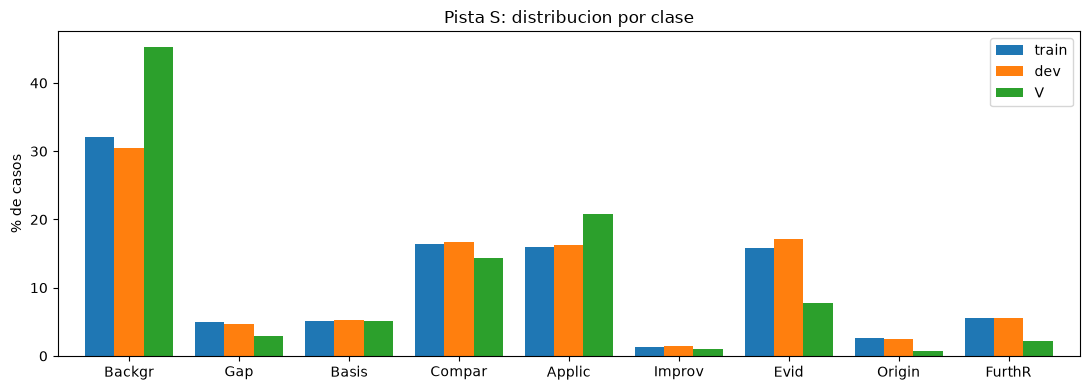

In [17]:
DISTRIBUCION = pd.DataFrame({n: por_clase(CONJ[n]) for n in ("train", "dev", "V")})
PROPORCION = (100 * DISTRIBUCION / DISTRIBUCION.sum()).round(2)
RAZON_DESBALANCE = {n: round(float(DISTRIBUCION[n].max() / max(DISTRIBUCION[n].min(), 1)), 1) for n in DISTRIBUCION}
print(pd.concat({"n": DISTRIBUCION, "%": PROPORCION}, axis=1).to_string())
print("razon de desbalance (mayor / menor):", RAZON_DESBALANCE)

fig, ax = plt.subplots(figsize=(11, 4))
PROPORCION.plot.bar(ax=ax, width=0.8)
ax.set_ylabel("% de casos")
ax.set_title(f"Pista {PISTA}: distribucion por clase")
ax.set_xticklabels(CORTAS, rotation=0)
plt.tight_layout()
plt.show()

### 3.3 Calidad de etiqueta

confianza                         Alta  Baja  Media
clase                                              
Background                        68.7   0.7   30.6
Gap                               40.5   0.0   59.5
Basis                             39.6   2.1   58.2
Comparison                        81.8   0.5   17.7
Application                       88.1   0.2   11.7
Improvement / Modification        86.1   0.0   13.9
Evidence                          50.1   1.4   48.5
Identification of the Originator  67.4   1.0   31.6
Further Reading                   67.2   4.1   28.7


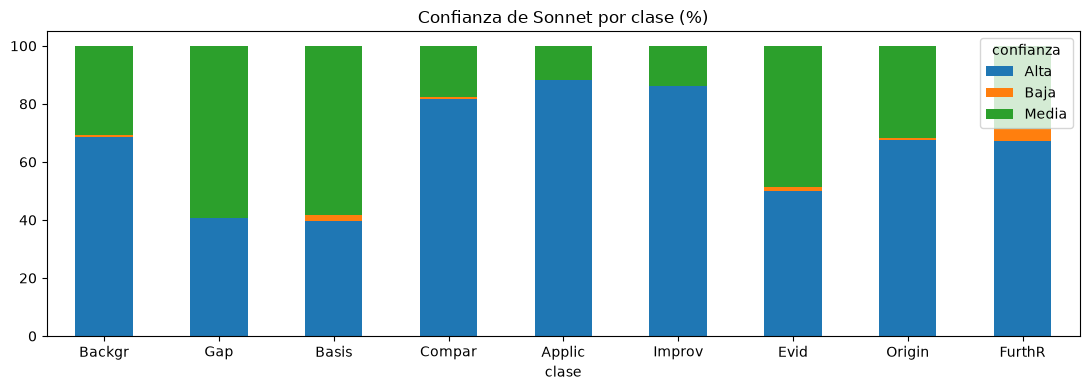

Acuerdo M <-> S: {'train+dev': {'n': 5153, 'acuerdo_%': 66.3, 'kappa': 0.6}, 'V': {'n': 3318, 'acuerdo_%': 72.5, 'kappa': 0.629}}


In [18]:
def entropia(dist: list[float]) -> float:
    return float(-sum(p * math.log(p) for p in dist if p > 0))


if PISTA == "M":
    QL = [x for x in TRAIN_DEV if x["fuente"] == "qlora"]
    P_CLASE = pd.DataFrame({"clase": [CLASES[x["indice"]] for x in QL], "p": [x["p"] for x in QL],
                            "entropia": [entropia(x["objetivo"]) for x in QL]})
    print(P_CLASE.groupby("clase")[["p", "entropia"]].describe().round(3).reindex(CLASES).to_string())
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].boxplot([P_CLASE.loc[P_CLASE.clase == c, "p"] for c in CLASES], tick_labels=CORTAS)
    ax[0].set_title("p del QLoRA por clase (filas qlora)")
    ax[1].hist(P_CLASE["entropia"], bins=40)
    ax[1].set_title(f"Entropia de la distribucion KD (max ln 9 = {math.log(9):.2f})")
    plt.tight_layout()
    plt.show()
else:
    CONF_CLASE = pd.crosstab(pd.Series([CLASES[x["indice"]] for x in TRAIN_DEV], name="clase"),
                             pd.Series([x["confianza"] for x in TRAIN_DEV], name="confianza"), normalize="index").reindex(CLASES)
    print((100 * CONF_CLASE).round(1).to_string())
    (100 * CONF_CLASE).plot.bar(stacked=True, figsize=(11, 4), title="Confianza de Sonnet por clase (%)").set_xticklabels(CORTAS, rotation=0)
    plt.tight_layout()
    plt.show()

# Acuerdo M <-> S en los ids compartidos
OTRA_TRAIN = dict(zip(*leer_csv(DATOS / CFG["otra_train"], usecols=["context_id", "etiqueta_entrenamiento"]).values.T))
OTRA_V = dict(zip(*leer_csv(DATOS / CFG["otra_v"], usecols=["context_id", "etiqueta_entrenamiento"]).values.T))
ACUERDO = {}
for nombre, filas, otra in (("train+dev", TRAIN_DEV, OTRA_TRAIN), ("V", CONJ["V"], OTRA_V)):
    comunes = [x for x in filas if x["context_id"] in otra]
    a = [x["indice"] for x in comunes]
    b = [INDICE[otra[x["context_id"]]] for x in comunes]
    ACUERDO[nombre] = {"n": len(comunes), "acuerdo_%": round(float(100 * np.mean(np.array(a) == np.array(b))), 1),
                       "kappa": round(float(cohen_kappa_score(a, b)), 3)}
print("Acuerdo M <-> S:", ACUERDO)

### 3.4 Longitudes en tokens y truncamiento (presupuesto de 512)

                count   mean    std   min    50%    90%     99%      max
contexto      10038.0   86.3   13.4  63.0   84.0   99.0   141.6    215.0
titulo        10038.0    7.9    2.5   2.0    8.0   11.0    14.0     23.0
abstract      10038.0  198.4  377.6  11.0  121.0  214.0  1457.0  13764.0
chunk_1       10038.0  153.4   67.7   4.0  142.0  243.0   357.6    560.0
chunk_2       10038.0  158.1   71.5   5.0  146.0  255.0   365.0    426.0
chunk_3       10038.0  160.9   74.8  13.0  149.0  266.0   365.0    503.0
chunks_total  10038.0  472.4  139.2  46.0  454.0  653.0   885.6   1192.0
A_total       10038.0  296.6  377.5  95.0  220.0  313.0  1558.6  13863.0

% de casos con el segmento truncado (train):
                     A      AB
abstract          6.26    6.26
chunk_1            NaN   75.74
chunk_2            NaN   76.68
chunk_3            NaN   76.25
contexto          0.13    0.13
titulo            0.00    0.00
longitud_media  240.20  508.30


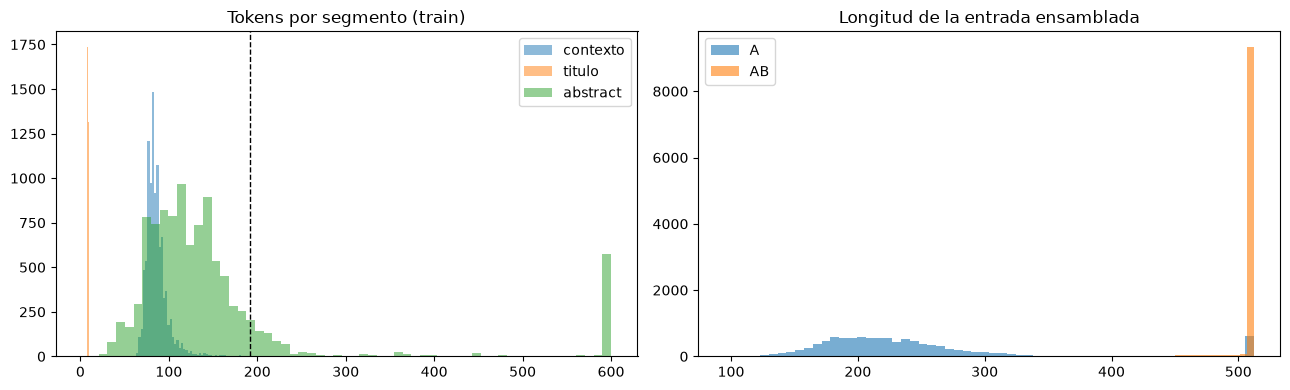

In [19]:
LONG = pd.DataFrame([{**e["longitudes"]} for e in EJEMPLOS[("train", "AB")]])
LONG["chunks_total"] = LONG[["chunk_1", "chunk_2", "chunk_3"]].sum(axis=1)
LONG["A_total"] = LONG[["contexto", "titulo", "abstract"]].sum(axis=1) + 4
print(LONG.describe(percentiles=[0.5, 0.9, 0.99]).round(1).T.to_string())


def truncamiento(ejemplos: list[dict]) -> pd.Series:
    df = pd.DataFrame([e["truncados"] for e in ejemplos])
    return (100 * (df > 0).mean()).round(2)


TRUNC = pd.DataFrame({e: truncamiento(EJEMPLOS[("train", e)]) for e in ("A", "AB")})
TRUNC.loc["longitud_media"] = [round(np.mean([len(x["input_ids"]) for x in EJEMPLOS[("train", e)]]), 1) for e in ("A", "AB")]
print("\n% de casos con el segmento truncado (train):")
print(TRUNC.to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for col in ("contexto", "titulo", "abstract"):
    ax[0].hist(LONG[col].clip(upper=600), bins=60, alpha=0.5, label=col)
ax[0].axvline(TOPE_CONTEXTO, color="k", ls="--", lw=1)
ax[0].legend()
ax[0].set_title("Tokens por segmento (train)")
ax[1].hist([len(x["input_ids"]) for x in EJEMPLOS[("train", "A")]], bins=60, alpha=0.6, label="A")
ax[1].hist([len(x["input_ids"]) for x in EJEMPLOS[("train", "AB")]], bins=60, alpha=0.6, label="AB")
ax[1].legend()
ax[1].set_title("Longitud de la entrada ensamblada")
plt.tight_layout()
plt.show()

### 3.5 Duplicados y dependencia

duplicados exactos de contexto en train+dev: 202 | pares casi-duplicados dentro de train+dev: 1296 (2s)
casi-duplicados entre conjuntos antes de L10: {'train~dev': 66, 'train~V': 7, 'train~gold': 2, 'dev~V': 3, 'dev~gold': 0, 'V~gold': 0}
       citas por citante  citas por citado
count            5309.00           2360.00
mean                2.23              5.02
std                 1.80             11.53
min                 1.00              1.00
25%                 1.00              1.00
50%                 2.00              2.00
75%                 3.00              5.00
max                17.00            229.00
el 10 % de citados mas citados concentra el 49.9 % de las citas


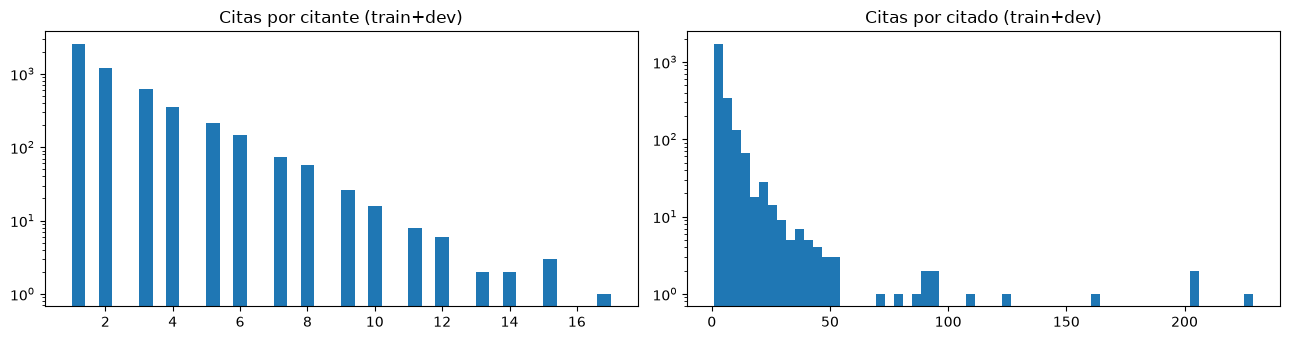

In [20]:
textos_train = Counter(" ".join(x["texto"].split()) for x in TRAIN_DEV)
DUP_EXACTOS = sum(n - 1 for n in textos_train.values() if n > 1)
t = time.time()
CASI_DUP_TRAIN = casi_duplicados(textos(TRAIN_DEV), textos(TRAIN_DEV))
print(f"duplicados exactos de contexto en train+dev: {DUP_EXACTOS} | pares casi-duplicados dentro de train+dev: "
      f"{len(CASI_DUP_TRAIN) // 2} ({time.time() - t:.0f}s)")
print("casi-duplicados entre conjuntos antes de L10:", {k: len(v) for k, v in L10_INICIAL.items()})

POR_CITANTE = pd.Series(Counter(x["citing_id"] for x in TRAIN_DEV))
POR_CITADO = pd.Series(Counter(x["cited_id"] for x in TRAIN_DEV))
print(pd.DataFrame({"citas por citante": POR_CITANTE.describe(), "citas por citado": POR_CITADO.describe()}).round(2).to_string())
print(f"el 10 % de citados mas citados concentra el {100 * POR_CITADO.nlargest(max(1, len(POR_CITADO) // 10)).sum() / POR_CITADO.sum():.1f} % de las citas")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].hist(POR_CITANTE, bins=40, log=True)
ax[0].set_title("Citas por citante (train+dev)")
ax[1].hist(POR_CITADO, bins=60, log=True)
ax[1].set_title("Citas por citado (train+dev)")
plt.tight_layout()
plt.show()

### 3.6 Cobertura V1 frente a V2

Articulos citados (todos los requeridos) por estado V1 x V2:
v2             ocl_404    ok  sin_descargar  sin_parrafos
v1                                                       
ocl_404             13     0              0             0
ok                   0  1853              0             0
parrafo_largo        0  1272              0             0
sin_descargar        0     0              3             0
sin_parrafos         0     0              0             4
articulos rescatados por V2: 1272 de 3145
gold: V1 839 -> V2 1532 citas con entrada AB

parrafos largos (>300 palabras o >5000 caracteres): 2020 en 1272 articulos
count     2020.0
mean       549.0
std       1548.0
min        301.0
50%        358.0
90%        525.0
99%       4533.0
max      25462.0

parrafos patologicos (>2000 palabras): 29; muestra:
  P03-1056 p1 [] 25462 palabras: v Ô Ð h Û ¥ ä $ Î á Ð × Ð h Û Ü Û ) Ù r Ò h Ñ Ð h Ï d ä ù Ò h × ç Î Ñ ® Û Ð h Ï ¢ Ö x Ú I Ð Ö h Î h ð & % o Ò h Ñ ¦ Î Ñ ¦ Î x Ô Õ x Î Ï × ¦ Û ¥ ä h 

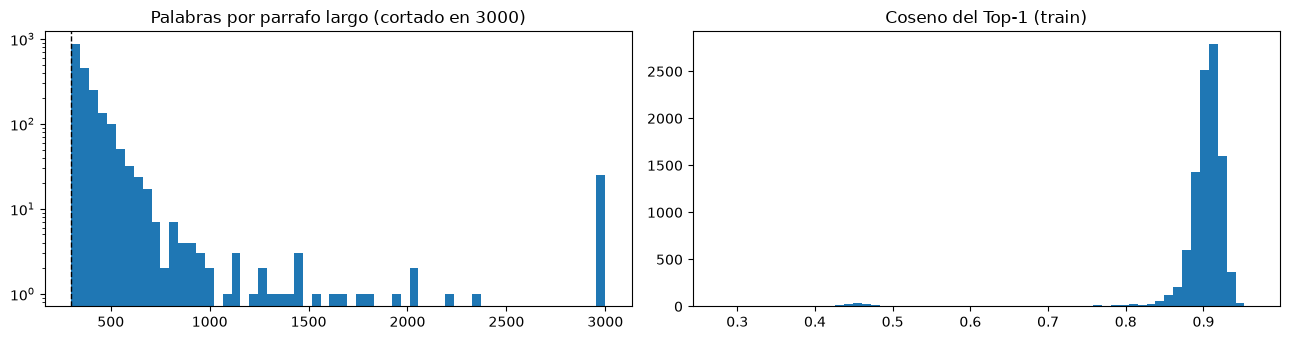

In [21]:
CITADOS_USO = {x["cited_id"] for n in ("train", "dev", "V") for x in CONJ[n]} | {x["cited_id"] for x in GOLD_FILAS}
estados = pd.DataFrame([{"cited_id": c, "v1": INFO_CITADOS[c]["motivo_v1"] or "ok", "v2": INFO_CITADOS[c]["motivo_v2"] or "ok"}
                        for c in CITADOS_REQUERIDOS])
print("Articulos citados (todos los requeridos) por estado V1 x V2:")
print(pd.crosstab(estados["v1"], estados["v2"]).to_string())
RESCATADOS = estados[(estados.v1 != "ok") & (estados.v2 == "ok")]
print(f"articulos rescatados por V2: {len(RESCATADOS)} de {len(estados)}")
print(f"gold: V1 {COBERTURA_GOLD_V1['ok']} -> V2 {len(COB_GOLD)} citas con entrada AB")

LARGOS = pd.DataFrame([p for c in CITADOS_REQUERIDOS for p in INFO_CITADOS[c]["largos"]])
print(f"\nparrafos largos (>{MAX_PALABRAS} palabras o >{MAX_CARACTERES} caracteres): {len(LARGOS)} en {LARGOS['cited_id'].nunique()} articulos")
print(LARGOS["palabras"].describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_string())
PATOLOGICOS = LARGOS[LARGOS["palabras"] > PALABRAS_PATOLOGICO].sort_values("palabras", ascending=False)
print(f"\nparrafos patologicos (>{PALABRAS_PATOLOGICO} palabras): {len(PATOLOGICOS)}; muestra:")
for r in PATOLOGICOS.head(5).itertuples():
    print(f"  {r.cited_id} p{r.numero} [{r.seccion[:40]}] {r.palabras} palabras: {r.extracto[:200]}...")

PERF = pd.DataFrame([{"posicion": i, "perfil": c["perfil"], "similitud": c["similitud"]}
                     for x in CONJ["train"] for i, c in enumerate(PERFILES_TOP3[x["context_id"]], 1)])
print("\nperfil de seccion en el Top-3 (train, % por posicion):")
print((100 * pd.crosstab(PERF["perfil"], PERF["posicion"], normalize="columns")).round(1).to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].hist(LARGOS["palabras"].clip(upper=3000), bins=60, log=True)
ax[0].axvline(MAX_PALABRAS, color="k", ls="--", lw=1)
ax[0].set_title("Palabras por parrafo largo (cortado en 3000)")
ax[1].hist(PERF.loc[PERF.posicion == 1, "similitud"], bins=60)
ax[1].set_title("Coseno del Top-1 (train)")
plt.tight_layout()
plt.show()

### 3.7 Implicaciones para el modelado

In [22]:
CONTEO_TRAIN = DISTRIBUCION["train"]
MINORITARIAS = list(CONTEO_TRAIN.nsmallest(3).index)
IMPLICACIONES = [
    f"Desbalance {RAZON_DESBALANCE['train']}:1 en train ({CONTEO_TRAIN.idxmax()} {PROPORCION.loc[CONTEO_TRAIN.idxmax(), 'train']} % "
    f"frente a {CONTEO_TRAIN.idxmin()} {PROPORCION.loc[CONTEO_TRAIN.idxmin(), 'train']} %). El F1-macro pesa lo mismo las 9 clases, "
    f"así que las estrategias E1–E5 y el ajuste post-hoc pueden mover la métrica sin cambiar la accuracy.",
    f"Las 3 clases minoritarias en train son {', '.join(MINORITARIAS)}; se reporta su F1 por separado en V.",
    f"Train y V difieren en la mezcla de clases (máxima diferencia absoluta {(PROPORCION['train'] - PROPORCION['V']).abs().max():.1f} pp), "
    "así que el prior de train (E4) no es el de evaluación. El ajuste post-hoc sobre dev no corrige ese cambio.",
    f"Acuerdo M↔S: κ = {ACUERDO['train+dev']['kappa']} en train y {ACUERDO['V']['kappa']} en V. "
    "Ese techo de ruido de etiqueta limita cuánto puede ganar cualquier estrategia sobre V.",
    f"Truncamiento: en A se recorta el abstract en el {TRUNC.loc['abstract', 'A']} % de los casos. En AB, los chunks reciben "
    f"solo los tokens sobrantes: el chunk 3 se recorta en el {TRUNC.loc['chunk_3', 'AB']} % de los casos.",
    f"Dependencia: la mediana de citas por citado es {POR_CITADO.median():.0f}, con cola larga (máximo {POR_CITADO.max()}). "
    "El bootstrap del gold se hace por citante.",
]
for i in IMPLICACIONES:
    print("-", i)

- Desbalance 24.4:1 en train (Background 32.09 % frente a Improvement / Modification 1.32 %). El F1-macro pesa lo mismo las 9 clases, así que las estrategias E1–E5 y el ajuste post-hoc pueden mover la métrica sin cambiar la accuracy.
- Las 3 clases minoritarias en train son Improvement / Modification, Identification of the Originator, Gap; se reporta su F1 por separado en V.
- Train y V difieren en la mezcla de clases (máxima diferencia absoluta 13.2 pp), así que el prior de train (E4) no es el de evaluación. El ajuste post-hoc sobre dev no corrige ese cambio.
- Acuerdo M↔S: κ = 0.6 en train y 0.629 en V. Ese techo de ruido de etiqueta limita cuánto puede ganar cualquier estrategia sobre V.
- Truncamiento: en A se recorta el abstract en el 6.26 % de los casos. En AB, los chunks reciben solo los tokens sobrantes: el chunk 3 se recorta en el 76.25 % de los casos.
- Dependencia: la mediana de citas por citado es 2, con cola larga (máximo 229). El bootstrap del gold se hace por citante.


## 4. Modelo y entrenamiento

Paridad con #104:
- **Modelo**: SciBERT (atención eager) + Dropout 0,1 + Linear(768, 9) sobre [CLS].
- **Optimización**: AdamW con weight decay 0,01, sin decay en bias ni LayerNorm. Warmup lineal del 10 %, lote 8×2 y clip 1,0.
- **Ejecución**: bf16 con autocast y padding dinámico.
- **Parada**: máximo 4 épocas, con paciencia 2 sobre el F1-macro de dev; se queda el mejor estado.

`perdida(estrategia, ...)` recibe siempre una distribución objetivo: one-hot para etiquetas duras y la distribución KD en las
filas qlora de M. Con objetivos one-hot, E1 coincide con `CrossEntropyLoss(weight)`.

| id | estrategia |
|---|---|
| E0 | CE sin pesos |
| E1 | CE con pesos inversos n/(9·n_c) (#104) |
| E2 | CE con pesos raíz inversa |
| E3 | Focal γ=2 con pesos class-balanced ((1−β)/(1−β^n_c), β=0,999) |
| E4 | Logit-adjusted: logits + τ·log π_train durante el entrenamiento, logits crudos en la inferencia |
| E5 | `WeightedRandomSampler` (peso raíz inversa por muestra) + CE sin pesos |
| +PH | sesgo por clase sumado a los logits, ajustado en dev por ascenso coordenado para maximizar el F1-macro |

Cada corrida guarda un JSON con métricas, sesgos e historial, los logits (`.npz`) y las predicciones ciegas del gold (`.jsonl`).
Si el JSON ya existe, la corrida no se repite.

In [23]:
CONTEO = np.array([CONTEO_TRAIN[c] for c in CLASES], dtype=float)
N_TRAIN = CONTEO.sum()
INVERSOS = np.where(CONTEO > 0, N_TRAIN / (N_CLASES * np.maximum(CONTEO, 1)), 0.0)
CB = (1 - BETA_CB) / (1 - BETA_CB ** np.maximum(CONTEO, 1))
CB = CB / CB.sum() * N_CLASES
PRIOR = np.maximum(CONTEO, 1) / np.maximum(CONTEO, 1).sum()
PESOS = {"E1": torch.tensor(INVERSOS, dtype=torch.float32, device=DISPOSITIVO),
         "E2": torch.tensor(np.sqrt(INVERSOS), dtype=torch.float32, device=DISPOSITIVO),
         "E3": torch.tensor(CB, dtype=torch.float32, device=DISPOSITIVO)}
LOG_PRIOR = torch.tensor(np.log(PRIOR), dtype=torch.float32, device=DISPOSITIVO)
PESO_MUESTRA_E5 = np.sqrt(INVERSOS)
print(pd.DataFrame({"n_train": CONTEO.astype(int), "E1 inverso": INVERSOS, "E2 raiz": np.sqrt(INVERSOS), "E3 class-balanced": CB,
                    "E4 prior": PRIOR}, index=CLASES).round(3).to_string())


def perdida(estrategia: str, logits: torch.Tensor, objetivo: torch.Tensor) -> torch.Tensor:
    logits = logits.float()
    if estrategia == "E4":
        logits = logits + TAU_LA * LOG_PRIOR
    logp = torch.log_softmax(logits, dim=-1)
    if estrategia == "E3":
        alfa = PESOS["E3"]
        por_muestra = -(objetivo * alfa * (1 - logp.exp()) ** GAMMA_FOCAL * logp).sum(-1)
        w = (objetivo * alfa).sum(-1)
        return por_muestra.sum() / w.sum()
    ce = -(objetivo * logp).sum(-1)
    if estrategia in ("E1", "E2"):
        w = (objetivo * PESOS[estrategia]).sum(-1)
        return (ce * w).sum() / w.sum()
    return ce.mean()   # E0, E5 (y E4 sobre los logits ajustados)

                                  n_train  E1 inverso  E2 raiz  E3 class-balanced  E4 prior
Background                           3221       0.346    0.588              0.381     0.321
Gap                                   503       2.217    1.489              0.926     0.050
Basis                                 512       2.178    1.476              0.914     0.051
Comparison                           1650       0.676    0.822              0.453     0.164
Application                          1606       0.694    0.833              0.458     0.160
Improvement / Modification            132       8.449    2.907              2.960     0.013
Evidence                             1593       0.700    0.837              0.460     0.159
Identification of the Originator      261       4.273    2.067              1.594     0.026
Further Reading                       560       1.992    1.411              0.854     0.056


In [24]:
class ClasificadorCLS(nn.Module):
    def __init__(self, semilla: int):
        super().__init__()
        # atencion "eager": SDPA tiene retroceso no determinista en CUDA
        self.encoder = AutoModel.from_pretrained(SCIBERT, attn_implementation="eager")
        torch.manual_seed(semilla)   # la cabeza se inicializa con la semilla de la corrida
        self.dropout = nn.Dropout(DROPOUT)
        self.cabeza = nn.Linear(self.encoder.config.hidden_size, N_CLASES)

    def forward(self, input_ids, attention_mask):
        cls = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        return self.cabeza(self.dropout(cls))


def lote_tensores(ejemplos: list[dict]) -> tuple[torch.Tensor, torch.Tensor]:
    largo = max(len(e["input_ids"]) for e in ejemplos)
    ids = torch.full((len(ejemplos), largo), PAD, dtype=torch.long)
    mask = torch.zeros((len(ejemplos), largo), dtype=torch.long)
    for i, e in enumerate(ejemplos):
        ids[i, :len(e["input_ids"])] = torch.tensor(e["input_ids"])
        mask[i, :len(e["input_ids"])] = 1
    return ids.to(DISPOSITIVO), mask.to(DISPOSITIVO)


def autocast():
    return torch.autocast(device_type=DISPOSITIVO.type, dtype=torch.bfloat16, enabled=DISPOSITIVO.type == "cuda")


@torch.inference_mode()
def logits_de(modelo: nn.Module, ejemplos: list[dict]) -> np.ndarray:
    # Inferencia por lotes ordenados por longitud; devuelve los logits en el orden de `ejemplos`
    modelo.eval()
    orden = sorted(range(len(ejemplos)), key=lambda i: len(ejemplos[i]["input_ids"]))
    salida = np.zeros((len(ejemplos), N_CLASES), dtype=np.float32)
    for ini in range(0, len(orden), BATCH_INFERENCIA):
        idx = orden[ini:ini + BATCH_INFERENCIA]
        ids, mask = lote_tensores([ejemplos[i] for i in idx])
        with autocast():
            salida[idx] = modelo(ids, mask).float().cpu().numpy()
    return salida


def matriz_confusion(y: np.ndarray, pred: np.ndarray) -> np.ndarray:
    return np.bincount(np.asarray(y) * N_CLASES + np.asarray(pred), minlength=N_CLASES ** 2).reshape(N_CLASES, N_CLASES)


def f1_por_clase(mat: np.ndarray) -> np.ndarray:
    # zero_division = 0; acepta matrices apiladas (..., 9, 9)
    tp = np.diagonal(mat, axis1=-2, axis2=-1).astype(float)
    den = mat.sum(-1) + mat.sum(-2)
    return np.divide(2 * tp, den, out=np.zeros_like(tp), where=den > 0)


def metricas(y, pred) -> dict:
    # macro sobre las 9 clases (tambien las sin soporte), micro = accuracy, ponderado por soporte
    mat = matriz_confusion(y, pred)
    f1 = f1_por_clase(mat)
    soporte = mat.sum(1)
    n = mat.sum()
    return {"n": int(n), "accuracy": float(np.trace(mat) / n), "f1_macro": float(f1.mean()), "f1_micro": float(np.trace(mat) / n),
            "f1_weighted": float((f1 * soporte).sum() / n), "f1_clase": f1.tolist(), "soporte": soporte.tolist(),
            "confusion": mat.tolist()}


def ajustar_sesgos(logits: np.ndarray, y: np.ndarray) -> np.ndarray:
    # Ascenso coordenado sobre un sesgo por clase (sumado a log-softmax) que maximiza el F1-macro de dev
    logp = logits - np.logaddexp.reduce(logits, axis=1, keepdims=True)
    sesgos = np.zeros(N_CLASES)
    mejor = metricas(y, (logp + sesgos).argmax(1))["f1_macro"]
    for _ in range(RONDAS_SESGOS):
        cambio = False
        for c in range(N_CLASES):
            for v in GRILLA_SESGOS:
                prueba = sesgos.copy()
                prueba[c] = v
                f1 = metricas(y, (logp + prueba).argmax(1))["f1_macro"]
                if f1 > mejor + 1e-12:
                    mejor, sesgos, cambio = f1, prueba, True
        if not cambio:
            break
    return sesgos


def predecir(logits: np.ndarray, sesgos: np.ndarray | None = None) -> np.ndarray:
    if sesgos is None:
        return logits.argmax(1)
    return (logits - np.logaddexp.reduce(logits, axis=1, keepdims=True) + sesgos).argmax(1)

In [25]:
def entrenar(estrategia: str, entrada: str, lr: float, semilla: int) -> tuple[nn.Module, dict]:
    train, dev = EJEMPLOS[("train", entrada)], EJEMPLOS[("dev", entrada)]
    y_dev = np.array([e["indice"] for e in dev])
    fijar_semillas(semilla)
    modelo = ClasificadorCLS(semilla).to(DISPOSITIVO)
    fijar_semillas(semilla)   # como #104: la semilla se vuelve a fijar despues de construir el modelo
    sin_decay = ("bias", "LayerNorm.weight")
    grupos = [{"params": [p for n, p in modelo.named_parameters() if not any(k in n for k in sin_decay)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in modelo.named_parameters() if any(k in n for k in sin_decay)], "weight_decay": 0.0}]
    optimizador = torch.optim.AdamW(grupos, lr=lr)
    lotes_por_epoca = math.ceil(len(train) / BATCH)
    total = math.ceil(lotes_por_epoca / ACUMULACION) * EPOCAS
    plan = get_linear_schedule_with_warmup(optimizador, round(WARMUP * total), total)
    generador = torch.Generator().manual_seed(semilla)
    if estrategia == "E5":
        pesos = [float(PESO_MUESTRA_E5[e["indice"]]) for e in train]
        muestreador = WeightedRandomSampler(pesos, num_samples=len(train), replacement=True, generator=generador)
        cargador = DataLoader(train, batch_size=BATCH, sampler=muestreador, collate_fn=lambda b: b)
    else:
        cargador = DataLoader(train, batch_size=BATCH, shuffle=True, generator=generador, collate_fn=lambda b: b)
    historial, mejor_f1, mejor_estado, mejor_epoca, sin_mejora = [], -1.0, None, 0, 0
    for epoca in range(1, EPOCAS + 1):
        modelo.train()
        t0, acumulado = time.time(), 0.0
        optimizador.zero_grad(set_to_none=True)
        for i, lote in enumerate(cargador, 1):
            ids, mask = lote_tensores(lote)
            objetivo = torch.tensor([e["objetivo"] for e in lote], dtype=torch.float32, device=DISPOSITIVO)
            with autocast():
                logits = modelo(ids, mask)
            valor = perdida(estrategia, logits, objetivo)
            (valor / ACUMULACION).backward()
            acumulado += float(valor.detach())
            if i % ACUMULACION == 0 or i == lotes_por_epoca:
                torch.nn.utils.clip_grad_norm_(modelo.parameters(), CLIP)
                optimizador.step()
                plan.step()
                optimizador.zero_grad(set_to_none=True)
        f1_dev = metricas(y_dev, logits_de(modelo, dev).argmax(1))["f1_macro"]
        historial.append({"epoca": epoca, "loss_train": acumulado / lotes_por_epoca, "f1_macro_dev": f1_dev,
                          "segundos": round(time.time() - t0, 1)})
        print(f"    epoca {epoca}: loss {historial[-1]['loss_train']:.4f} | F1-macro dev {f1_dev:.4f} | {historial[-1]['segundos']:.0f}s")
        if f1_dev > mejor_f1:
            mejor_f1, mejor_epoca, sin_mejora = f1_dev, epoca, 0
            mejor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                break
    modelo.load_state_dict(mejor_estado)
    return modelo, {"historial": historial, "mejor_epoca": mejor_epoca, "epocas_ejecutadas": len(historial), "f1_macro_dev": mejor_f1}


def nombre_corrida(estrategia: str, entrada: str, lr: float, semilla: int) -> str:
    return f"{PISTA}-{entrada}-{estrategia}-lr{lr:g}-s{semilla}"


def resumen_v(m: dict) -> dict:
    return {"f1_macro": m["f1_macro"], "accuracy": m["accuracy"], "f1_weighted": m["f1_weighted"],
            **{f"f1_{c}": m["f1_clase"][INDICE[c]] for c in MINORITARIAS}}


def correr(estrategia: str, entrada: str, lr: float, semilla: int, fase: str) -> dict:
    nombre = nombre_corrida(estrategia, entrada, lr, semilla)
    ruta = CORRIDAS / f"{nombre}.json"
    if ruta.is_file():
        r = json.loads(ruta.read_text(encoding="utf-8"))
        assert r["sha_ids"] == SHA_IDS, f"{nombre}: la corrida guardada uso otros ids"
        print(f"[reanudada] {nombre}: F1-macro V {r['v']['f1_macro']:.4f} | con PH {r['v_ph']['f1_macro']:.4f}")
        return r
    print(f"[entrenando] {nombre}")
    t0 = time.time()
    modelo, info = entrenar(estrategia, entrada, lr, semilla)
    logits = {n: logits_de(modelo, EJEMPLOS[(n, entrada)]) for n in ("dev", "V", "gold")}
    del modelo
    liberar_gpu()
    y = {n: np.array([e["indice"] for e in EJEMPLOS[(n, entrada)]]) for n in ("dev", "V")}
    sesgos = ajustar_sesgos(logits["dev"], y["dev"])
    m_v, m_v_ph = metricas(y["V"], predecir(logits["V"])), metricas(y["V"], predecir(logits["V"], sesgos))
    ids_gold = [e["context_id"] for e in EJEMPLOS[("gold", entrada)]]
    np.savez_compressed(CORRIDAS / f"{nombre}.npz", **{f"logits_{n}": v for n, v in logits.items()}, ids_gold=np.array(ids_gold))
    pred, pred_ph = predecir(logits["gold"]), predecir(logits["gold"], sesgos)
    probs = torch.softmax(torch.tensor(logits["gold"]), dim=-1).numpy()
    with open(CORRIDAS / f"{nombre}.pred_test_gold.jsonl", "w", encoding="utf-8") as f:   # predicciones ciegas (sin etiquetas)
        for c, p, pp, pr in zip(ids_gold, pred, pred_ph, probs):
            f.write(json.dumps({"context_id": c, "pred": int(p), "pred_ph": int(pp), "probs": [round(float(x), 6) for x in pr]}) + "\n")
    r = {"nombre": nombre, "pista": PISTA, "entrada": entrada, "estrategia": estrategia, "lr": lr, "semilla": semilla, "fase": fase,
         **info, "sesgos_ph": sesgos.tolist(), "f1_macro_dev_ph": metricas(y["dev"], predecir(logits["dev"], sesgos))["f1_macro"],
         "v": resumen_v(m_v), "v_ph": resumen_v(m_v_ph), "v_metricas": m_v, "v_metricas_ph": m_v_ph,
         "n": {n: len(EJEMPLOS[(n, entrada)]) for n in ("train", "dev", "V", "gold")}, "sha_ids": SHA_IDS,
         "segundos": round(time.time() - t0, 1), "entorno": ENTORNO, "modo_prueba": MODO_PRUEBA}
    escribir_json(ruta, r)   # se escribe al final: marca la corrida como completa
    print(f"[ok {r['segundos']:.0f}s] {nombre}: F1-macro V {r['v']['f1_macro']:.4f} | con PH {r['v_ph']['f1_macro']:.4f}")
    return r

## 5. Experimentos (la selección se hace solo en V)

- **Fase 1.** E0–E5 con entrada A, semilla 42 y lr 3e-5.
- **Fase 2.** Las 2 mejores estrategias de la fase 1 se corren con lr 2e-5 y 5e-5. El puntaje de una corrida es el mayor
  F1-macro en V entre la versión sin PH y la versión con PH. Gana la combinación (estrategia, lr, PH) con mayor F1-macro en V;
  en empate se prefiere el lr menor y luego la versión sin PH.
- **Fase 3.** La configuración ganadora se corre con A y AB y las semillas 42, 1234 y 2026 (A con s42 se reutiliza). Además se
  corre E0 con entrada A y las mismas semillas, como línea base del desbalance. Todas las corridas dejan predicciones ciegas del
  gold, que no se puntúan aquí.

In [26]:
FASE1 = {e: correr(e, "A", LR_BASE, SEMILLA_FASE1, "fase1") for e in ESTRATEGIAS}


def puntaje(r: dict) -> float:
    return max(r["v"]["f1_macro"], r["v_ph"]["f1_macro"])


MEJORES = sorted(ESTRATEGIAS, key=lambda e: (-puntaje(FASE1[e]), e))[:N_MEJORES_FASE2]
print("mejores estrategias de la fase 1:", MEJORES)

[entrenando] S-A-E0-lr3e-05-s42


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 15898.41it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

    epoca 1: loss 1.0009 | F1-macro dev 0.6503 | 150s
    epoca 2: loss 0.4632 | F1-macro dev 0.7077 | 148s
    epoca 3: loss 0.2284 | F1-macro dev 0.7158 | 148s
    epoca 4: loss 0.0975 | F1-macro dev 0.7303 | 148s
[ok 608s] S-A-E0-lr3e-05-s42: F1-macro V 0.6647 | con PH 0.6580
[entrenando] S-A-E1-lr3e-05-s42


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 24434.03it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

    epoca 1: loss 1.2007 | F1-macro dev 0.6597 | 143s
    epoca 2: loss 0.5379 | F1-macro dev 0.6956 | 142s
    epoca 3: loss 0.2734 | F1-macro dev 0.7237 | 142s
    epoca 4: loss 0.1226 | F1-macro dev 0.7200 | 143s
[ok 583s] S-A-E1-lr3e-05-s42: F1-macro V 0.6467 | con PH 0.6567
[entrenando] S-A-E2-lr3e-05-s42


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 40378.62it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

... (3 outputs left out)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 59606.26it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

    epoca 1: loss 0.9725 | F1-macro dev 0.6701 | 143s
    epoca 2: loss 0.4527 | F1-macro dev 0.6945 | 141s
    epoca 3: loss 0.2253 | F1-macro dev 0.7023 | 141s
    epoca 4: loss 0.0930 | F1-macro dev 0.7249 | 143s
[ok 582s] S-A-E4-lr3e-05-s42: F1-macro V 0.6524 | con PH 0.6513
[entrenando] S-A-E5-lr3e-05-s42


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 53835.56it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

    epoca 1: loss 0.9900 | F1-macro dev 0.6941 | 145s
    epoca 2: loss 0.3694 | F1-macro dev 0.7265 | 147s
    epoca 3: loss 0.2133 | F1-macro dev 0.7121 | 146s
    epoca 4: loss 0.1220 | F1-macro dev 0.7391 | 146s
[ok 598s] S-A-E5-lr3e-05-s42: F1-macro V 0.6628 | con PH 0.6560
mejores estrategias de la fase 1: ['E0', 'E3']


In [27]:
FASE2 = {(e, lr): correr(e, "A", lr, SEMILLA_FASE1, "fase2") for e in MEJORES for lr in LRS_FASE2}
CANDIDATOS = []
for e in MEJORES:
    for r in [FASE1[e], *(FASE2[(e, lr)] for lr in LRS_FASE2)]:
        for ph in (False, True):
            CANDIDATOS.append({"estrategia": e, "lr": r["lr"], "ph": ph, "f1_macro_v": (r["v_ph"] if ph else r["v"])["f1_macro"]})
GANADOR = sorted(CANDIDATOS, key=lambda c: (-c["f1_macro_v"], c["lr"], c["ph"]))[0]
print("configuracion ganadora (solo V):", GANADOR)


def fila_tabla(r: dict) -> dict:
    return {"estrategia": r["estrategia"], "descripcion": ESTRATEGIAS[r["estrategia"]], "entrada": r["entrada"], "lr": f"{r['lr']:g}",
            "semilla": r["semilla"], "fase": r["fase"], "f1_macro_V": r["v"]["f1_macro"], "f1_macro_V_PH": r["v_ph"]["f1_macro"],
            "accuracy_V": r["v"]["accuracy"], "f1_weighted_V": r["v"]["f1_weighted"],
            **{f"f1_{c}_V": r["v"][f"f1_{c}"] for c in MINORITARIAS}, "f1_macro_dev": r["f1_macro_dev"],
            "epocas": r["epocas_ejecutadas"], "mejor_epoca": r["mejor_epoca"]}


TABLA_FASE12 = pd.DataFrame([fila_tabla(r) for r in [*FASE1.values(), *FASE2.values()]])
TABLA_FASE12.to_csv(EVIDENCIAS / f"{PISTA}_fases_1_2_V.csv", index=False)
print(TABLA_FASE12.drop(columns="descripcion").round(4).to_string(index=False))

[entrenando] S-A-E0-lr2e-05-s42


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 30108.45it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

    epoca 1: loss 1.0395 | F1-macro dev 0.6454 | 144s
    epoca 2: loss 0.4641 | F1-macro dev 0.7217 | 141s
    epoca 3: loss 0.2560 | F1-macro dev 0.7356 | 143s
    epoca 4: loss 0.1264 | F1-macro dev 0.7396 | 142s
[ok 583s] S-A-E0-lr2e-05-s42: F1-macro V 0.6643 | con PH 0.6610
[entrenando] S-A-E0-lr5e-05-s42


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17772.10it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

    epoca 1: loss 0.9815 | F1-macro dev 0.6183 | 143s
    epoca 2: loss 0.4723 | F1-macro dev 0.6901 | 144s
    epoca 3: loss 0.2232 | F1-macro dev 0.7007 | 141s
    epoca 4: loss 0.0766 | F1-macro dev 0.7182 | 142s
[ok 584s] S-A-E0-lr5e-05-s42: F1-macro V 0.6378 | con PH 0.6313
[entrenando] S-A-E3-lr2e-05-s42


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 34722.79it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

    epoca 1: loss 0.8062 | F1-macro dev 0.6581 | 143s
    epoca 2: loss 0.2830 | F1-macro dev 0.7147 | 142s
    epoca 3: loss 0.1321 | F1-macro dev 0.7162 | 144s
    epoca 4: loss 0.0615 | F1-macro dev 0.7316 | 141s
[ok 584s] S-A-E3-lr2e-05-s42: F1-macro V 0.6767 | con PH 0.6669
[entrenando] S-A-E3-lr5e-05-s42


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 46121.82it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

    epoca 1: loss 0.7551 | F1-macro dev 0.6629 | 143s
    epoca 2: loss 0.2894 | F1-macro dev 0.7062 | 142s
    epoca 3: loss 0.1196 | F1-macro dev 0.7188 | 142s
    epoca 4: loss 0.0375 | F1-macro dev 0.7236 | 143s
[ok 583s] S-A-E3-lr5e-05-s42: F1-macro V 0.6565 | con PH 0.6542
configuracion ganadora (solo V): {'estrategia': 'E3', 'lr': 2e-05, 'ph': False, 'f1_macro_v': 0.6767279129242103}
estrategia entrada    lr  semilla  fase  f1_macro_V  f1_macro_V_PH  accuracy_V  f1_weighted_V  f1_Improvement / Modification_V  f1_Identification of the Originator_V  f1_Gap_V  f1_macro_dev  epocas  mejor_epoca
        E0       A 3e-05       42 fase1      0.6647         0.6580      0.7957         0.7984                           0.5075                                 0.5818    0.4413        0.7303       4            4
        E1       A 3e-05       42 fase1      0.6467         0.6567      0.7875         0.7927                           0.5079                                 0.4324    0.4978        0

In [28]:
EST, LR, PH = GANADOR["estrategia"], GANADOR["lr"], GANADOR["ph"]
FASE3 = {(entrada, s): correr(EST, entrada, LR, s, "fase3") for entrada in ("A", "AB") for s in SEMILLAS}
FASE3_E0 = {s: correr("E0", "A", LR_BASE, s, "fase3_e0") for s in SEMILLAS}

filas = []
for etiqueta, corridas, ph in ((f"mejor-A ({EST}, lr {LR:g}, PH={PH})", [FASE3[("A", s)] for s in SEMILLAS], PH),
                               (f"mejor-AB ({EST}, lr {LR:g}, PH={PH})", [FASE3[("AB", s)] for s in SEMILLAS], PH),
                               (f"E0-A (lr {LR_BASE:g}, sin PH)", list(FASE3_E0.values()), False)):
    valores = pd.DataFrame([r["v_ph"] if ph else r["v"] for r in corridas])
    filas.append({"modelo": etiqueta, "semillas": len(corridas),
                  **{f"{k}_media": valores[k].mean() for k in valores}, **{f"{k}_de": valores[k].std(ddof=1) for k in valores}})
TABLA_FASE3 = pd.DataFrame(filas)
TABLA_FASE3.to_csv(EVIDENCIAS / f"{PISTA}_fase3_V.csv", index=False)
print(TABLA_FASE3.round(4).T.to_string())

[reanudada] S-A-E3-lr2e-05-s42: F1-macro V 0.6767 | con PH 0.6669
[entrenando] S-A-E3-lr2e-05-s1234


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 16617.22it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

    epoca 1: loss 0.8088 | F1-macro dev 0.6599 | 142s
    epoca 2: loss 0.2848 | F1-macro dev 0.7364 | 144s
    epoca 3: loss 0.1370 | F1-macro dev 0.7245 | 142s
    epoca 4: loss 0.0638 | F1-macro dev 0.7238 | 143s
[ok 586s] S-A-E3-lr2e-05-s1234: F1-macro V 0.6400 | con PH 0.6515
[entrenando] S-A-E3-lr2e-05-s2026


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 57032.22it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

    epoca 1: loss 0.7806 | F1-macro dev 0.6764 | 142s
    epoca 2: loss 0.2929 | F1-macro dev 0.7228 | 143s
    epoca 3: loss 0.1379 | F1-macro dev 0.7335 | 144s
    epoca 4: loss 0.0594 | F1-macro dev 0.7470 | 143s
[ok 586s] S-A-E3-lr2e-05-s2026: F1-macro V 0.6592 | con PH 0.6684
[entrenando] S-AB-E3-lr2e-05-s42


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 45256.55it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

... (5 outputs left out)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 42853.96it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

    epoca 1: loss 0.9938 | F1-macro dev 0.6346 | 145s
    epoca 2: loss 0.4562 | F1-macro dev 0.7259 | 143s
    epoca 3: loss 0.2199 | F1-macro dev 0.7339 | 143s
    epoca 4: loss 0.0987 | F1-macro dev 0.7305 | 143s
[ok 588s] S-A-E0-lr3e-05-s1234: F1-macro V 0.6519 | con PH 0.6355
[entrenando] S-A-E0-lr3e-05-s2026


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 19163.07it/s]
[transformers] BertModel LOAD REPORT from: /home/carlos/.cache/huggingface/hub/models--allenai--scibert_scivocab_uncased/snapshots/24f92d32b1bfb0bcaf9ab193ff3ad01e87732fc1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archit

    epoca 1: loss 0.9695 | F1-macro dev 0.6858 | 142s
    epoca 2: loss 0.4621 | F1-macro dev 0.7029 | 146s
    epoca 3: loss 0.2332 | F1-macro dev 0.7193 | 142s
    epoca 4: loss 0.0909 | F1-macro dev 0.7175 | 144s
[ok 587s] S-A-E0-lr3e-05-s2026: F1-macro V 0.6678 | con PH 0.6462
                                                                          0                                  1                        2
modelo                                     mejor-A (E3, lr 2e-05, PH=False)  mejor-AB (E3, lr 2e-05, PH=False)  E0-A (lr 3e-05, sin PH)
semillas                                                                  3                                  3                        3
f1_macro_media                                                       0.6587                             0.6612                   0.6615
accuracy_media                                                       0.7938                             0.7943                   0.7952
f1_weighted_media                     

## 6. Evaluación en el test gold

Aquí se leen por primera vez las etiquetas del gold. Esta sección es idéntica en el 08 y el 09.

**Subconjuntos.** `todo` (1531 casos evaluables), `humano` (1061, sin `solo_opus`) y `concordancia` (186). Cada uno se evalúa
también en su intersección con la cobertura AB (`*_cob`).

**Métricas.** F1 macro, micro y ponderado, y accuracy. El macro promedia las 9 clases con `zero_division=0`. El F1 por clase
lleva un IC95 por bootstrap por citante, y se muestra la matriz de confusión.

**Contrastes.** Se usa `prueba_combinada`: la varianza junta la que hay entre semillas y la del bootstrap por citante (con la
misma remuestra para los dos brazos), con gl de Satterthwaite y TOST con δ = 0,02. Holm se aplica a los 3 contrastes dentro de
cada subconjunto; el TOST forma una familia aparte, también con Holm.
1. AB − A, el contraste primario: misma configuración, mismas semillas y mismos ids (`*_cob`).
2. mejor-A − E0-A: el efecto del manejo del desbalance.
3. mejor-A − ganador de #104 de la pista: predicciones ciegas ya calculadas por el notebook 07.

In [29]:
GOLD_DF = pd.read_csv(GOLD_CSV, encoding="utf-8-sig")
assert sha256_bytes(GOLD_CSV.read_bytes()) == GOLD_SHA
GOLD_DF = GOLD_DF[GOLD_DF["context_id"].isin({x["context_id"] for x in GOLD_USO})]
ETIQ = {r.context_id: int(r.indice) for r in GOLD_DF.itertuples() if r.evaluable}
FUENTE = dict(zip(GOLD_DF["context_id"], GOLD_DF["fuente"]))
SUBS = {"todo": set(ETIQ), "humano": {c for c in ETIQ if FUENTE[c] != "solo_opus"},
        "concordancia": {c for c in ETIQ if FUENTE[c] == "concordancia"}}
SUBS.update({f"{k}_cob": v & COB_GOLD for k, v in list(SUBS.items())})
if not MODO_PRUEBA:
    assert (len(SUBS["todo"]), len(SUBS["humano"]), len(SUBS["concordancia"])) == (1531, 1061, 186)
print({k: len(v) for k, v in SUBS.items()})

SOPORTE = pd.DataFrame({"train %": PROPORCION["train"], "V %": PROPORCION["V"],
                        "gold %": (100 * pd.Series(Counter(CLASES[i] for i in ETIQ.values())).reindex(CLASES, fill_value=0) / len(ETIQ)).round(2),
                        "gold n": pd.Series(Counter(CLASES[i] for i in ETIQ.values())).reindex(CLASES, fill_value=0)})
print(SOPORTE.to_string())

{'todo': 1531, 'humano': 1061, 'concordancia': 186, 'todo_cob': 1530, 'humano_cob': 1060, 'concordancia_cob': 186}
                                  train %    V %  gold %  gold n
Background                          32.09  45.30   28.09     430
Gap                                  5.01   2.92    6.66     102
Basis                                5.10   5.09    3.07      47
Comparison                          16.44  14.29   18.42     282
Application                         16.00  20.74   21.75     333
Improvement / Modification           1.32   1.02    4.38      67
Evidence                            15.87   7.78   14.89     228
Identification of the Originator     2.60   0.69    0.98      15
Further Reading                      5.58   2.17    1.76      27


In [30]:
def leer_preds(ruta: Path, campo: str = "pred") -> dict[str, int]:
    return {r["context_id"]: int(r[campo]) for r in leer_jsonl(ruta)}


def preds_corrida(estrategia: str, entrada: str, lr: float, semilla: int, ph: bool) -> dict[str, int]:
    return leer_preds(CORRIDAS / f"{nombre_corrida(estrategia, entrada, lr, semilla)}.pred_test_gold.jsonl", "pred_ph" if ph else "pred")


MODELOS = {
    "mejor-A": {s: preds_corrida(EST, "A", LR, s, PH) for s in SEMILLAS},
    "mejor-AB": {s: preds_corrida(EST, "AB", LR, s, PH) for s in SEMILLAS},
    "E0-A": {s: preds_corrida("E0", "A", LR_BASE, s, False) for s in SEMILLAS},
    "ref-104": {s: leer_preds(DIR_REF_104 / f"{REF_104}-s{s}" / "pred_test_gold_todo.jsonl") for s in SEMILLAS},
}
DESCRIPCION = {"mejor-A": f"{EST} lr {LR:g} PH={PH}, entrada A", "mejor-AB": f"{EST} lr {LR:g} PH={PH}, entrada AB",
               "E0-A": f"E0 lr {LR_BASE:g} sin PH, entrada A", "ref-104": f"#104 {REF_104} (prediccion ciega previa)"}

FILAS_GOLD = []
for nombre, por_semilla in MODELOS.items():
    for sub, ids_sub in SUBS.items():
        ids_m = sorted(ids_sub)
        if not ids_m or any(c not in p for p in por_semilla.values() for c in ids_m):
            continue   # AB solo se mide en los subconjuntos *_cob
        for s, p in por_semilla.items():
            m = metricas([ETIQ[c] for c in ids_m], [p[c] for c in ids_m])
            FILAS_GOLD.append({"modelo": nombre, "descripcion": DESCRIPCION[nombre], "subconjunto": sub, "semilla": s, "n": m["n"],
                               **{k: m[k] for k in ("f1_macro", "f1_micro", "f1_weighted", "accuracy")}})
METRICAS_GOLD = pd.DataFrame(FILAS_GOLD)
AGREGADO_GOLD = (METRICAS_GOLD.groupby(["subconjunto", "modelo"], sort=False)
                 .agg(n=("n", "first"), semillas=("semilla", "nunique"),
                      **{f"{k}_media": (k, "mean") for k in ("f1_macro", "f1_micro", "f1_weighted", "accuracy")},
                      **{f"{k}_de": (k, "std") for k in ("f1_macro", "f1_micro", "f1_weighted", "accuracy")}).reset_index())
METRICAS_GOLD.to_csv(EVIDENCIAS / f"{PISTA}_gold_metricas_por_semilla.csv", index=False)
AGREGADO_GOLD.to_csv(EVIDENCIAS / f"{PISTA}_gold_metricas.csv", index=False)
for sub in SUBS:
    print(f"=== {sub} (n = {len(SUBS[sub])})")
    print(AGREGADO_GOLD[AGREGADO_GOLD.subconjunto == sub].drop(columns="subconjunto").round(4).to_string(index=False))

=== todo (n = 1531)
 modelo    n  semillas  f1_macro_media  f1_micro_media  f1_weighted_media  accuracy_media  f1_macro_de  f1_micro_de  f1_weighted_de  accuracy_de
mejor-A 1531         3          0.5844          0.7100             0.6958          0.7100       0.0124       0.0108          0.0103       0.0108
   E0-A 1531         3          0.5895          0.7113             0.6950          0.7113       0.0041       0.0000          0.0016       0.0000
ref-104 1531         3          0.5995          0.7213             0.7086          0.7213       0.0096       0.0062          0.0085       0.0062
=== humano (n = 1061)
 modelo    n  semillas  f1_macro_media  f1_micro_media  f1_weighted_media  accuracy_media  f1_macro_de  f1_micro_de  f1_weighted_de  accuracy_de
mejor-A 1061         3          0.5847          0.6887             0.6711          0.6887       0.0163       0.0101          0.0092       0.0101
   E0-A 1061         3          0.5870          0.6868             0.6678          0.686

In [31]:
# ---------------------------------------------------------------- bootstrap por citante y prueba combinada (reimplementados)
def _codigos(etiquetas: list[int], preds: list[list[int]]) -> np.ndarray:
    return np.asarray(etiquetas, dtype=np.int64)[None, :] * N_CLASES + np.asarray(preds, dtype=np.int64)


def _matrices(codigos: np.ndarray, pesos: np.ndarray) -> np.ndarray:
    # pesos (replicas, casos) -> matrices de confusion ponderadas (replicas, modelos, 9, 9)
    n_mod, n_casos = codigos.shape
    uno = np.zeros((n_casos, n_mod, N_CLASES ** 2))
    np.put_along_axis(uno, codigos.T[..., None], 1.0, axis=2)
    return (pesos @ uno.reshape(n_casos, -1)).reshape(pesos.shape[0], n_mod, N_CLASES, N_CLASES)


def _metrica_vectorial(mat: np.ndarray, metrica: str | None) -> np.ndarray:
    if metrica is None:
        return f1_por_clase(mat)
    if metrica == "f1_macro":
        return f1_por_clase(mat).mean(-1)
    total = mat.sum((-2, -1))
    if metrica == "accuracy":
        return np.diagonal(mat, axis1=-2, axis2=-1).sum(-1) / total
    return (f1_por_clase(mat) * mat.sum(-1)).sum(-1) / total   # f1_weighted


def _pesos_grupos(grupos: list[str], n: int, rng: np.random.Generator, lote: int = 250):
    # Cada replica remuestrea los citantes con reemplazo; cada caso pesa las veces que salio su citante
    posicion = {g: i for i, g in enumerate(sorted(set(grupos)))}
    idx = np.asarray([posicion[g] for g in grupos])
    hechos = 0
    while hechos < n:
        b = min(lote, n - hechos)
        conteo = rng.multinomial(len(posicion), np.full(len(posicion), 1 / len(posicion)), size=b)
        yield conteo[:, idx].astype(float)
        hechos += b


def metricas_bootstrap(etiquetas, preds, grupos, n=N_BOOTSTRAP, semilla=SEMILLA_BOOTSTRAP, metrica=None) -> np.ndarray:
    # Misma remuestra para todos los modelos: (replicas, modelos[, 9])
    codigos = _codigos(etiquetas, preds)
    rng = np.random.default_rng(semilla)
    return np.concatenate([_metrica_vectorial(_matrices(codigos, w), metrica) for w in _pesos_grupos(grupos, n, rng)], axis=0)


def metrica_observada(etiquetas, preds, metrica=None) -> np.ndarray:
    return _metrica_vectorial(_matrices(_codigos(etiquetas, preds), np.ones((1, len(etiquetas))))[0], metrica)


def _cdf_t(x: float, gl: float) -> float:
    return float(stats.norm.cdf(x) if math.isinf(gl) else stats.t.cdf(x, gl))


def _cuantil_t(q: float, gl: float) -> float:
    return float(stats.norm.ppf(q) if math.isinf(gl) else stats.t.ppf(q, gl))


def prueba_combinada(preds_x: list[list[int]], preds_a: list[list[int]], etiquetas: list[int], grupos: list[str],
                     n: int = N_BOOTSTRAP, semilla: int = SEMILLA_BOOTSTRAP, metrica: str = "f1_macro", delta: float = DELTA) -> dict:
    # t de X - A: v_sem = s^2(d_j)/k; v_art = var bootstrap por citante con semillas fijas; gl de Satterthwaite; TOST con delta
    k = len(preds_x)
    assert k == len(preds_a) and k >= 1
    preds = [*preds_x, *preds_a]
    obs = metrica_observada(etiquetas, preds, metrica)
    d_j = [float(obs[j] - obs[k + j]) for j in range(k)]
    d = math.fsum(d_j) / k
    s_d = float(np.std(d_j, ddof=1)) if k > 1 else 0.0
    v_sem = s_d ** 2 / k
    boot = metricas_bootstrap(etiquetas, preds, grupos, n, semilla, metrica)
    v_art = float((boot[:, :k] - boot[:, k:]).mean(1).var(ddof=1))
    se = math.sqrt(v_sem + v_art)
    gl = math.inf if v_sem == 0 or k < 2 else (v_sem + v_art) ** 2 / (v_sem ** 2 / (k - 1))
    if se == 0:
        p, p_inf, p_sup, ic95 = (1.0 if d == 0 else 0.0), (0.0 if d > -delta else 1.0), (0.0 if d < delta else 1.0), (d, d)
    else:
        p = 2 * (1 - _cdf_t(abs(d) / se, gl))
        p_inf = 1 - _cdf_t((d + delta) / se, gl)
        p_sup = _cdf_t((d - delta) / se, gl)
        t95 = _cuantil_t(0.975, gl)
        ic95 = (d - t95 * se, d + t95 * se)
    return {"diferencia": d, "diferencia_por_semilla": d_j, "sd_semillas": s_d, "v_sem": v_sem, "v_art": v_art, "se": se, "gl": gl,
            "p": float(p), "ic95_inf": ic95[0], "ic95_sup": ic95[1], "p_tost": float(max(p_inf, p_sup)), "semillas": k,
            "casos": len(etiquetas), "citantes": len(set(grupos))}


def holm(pvalores: dict) -> dict:
    orden = sorted(pvalores, key=lambda k: (pvalores[k], str(k)))
    m, previo, salida = len(orden), 0.0, {}
    for i, clave in enumerate(orden):
        previo = max(previo, min(1.0, (m - i) * pvalores[clave]))
        salida[clave] = previo
    return {k: salida[k] for k in pvalores}

modelo                           mejor-A   E0-A ref-104  mejor-A mejor-AB
subconjunto                         todo   todo    todo todo_cob todo_cob
clase                                                                    
Background                         0.750  0.751   0.762    0.750    0.763
Gap                                0.426  0.422   0.495    0.426    0.487
Basis                              0.396  0.400   0.402    0.396    0.407
Comparison                         0.784  0.781   0.787    0.784    0.798
Application                        0.822  0.825   0.833    0.822    0.829
Improvement / Modification         0.262  0.265   0.248    0.262    0.240
Evidence                           0.621  0.607   0.632    0.619    0.651
Identification of the Originator   0.468  0.478   0.464    0.468    0.461
Further Reading                    0.731  0.777   0.772    0.731    0.746


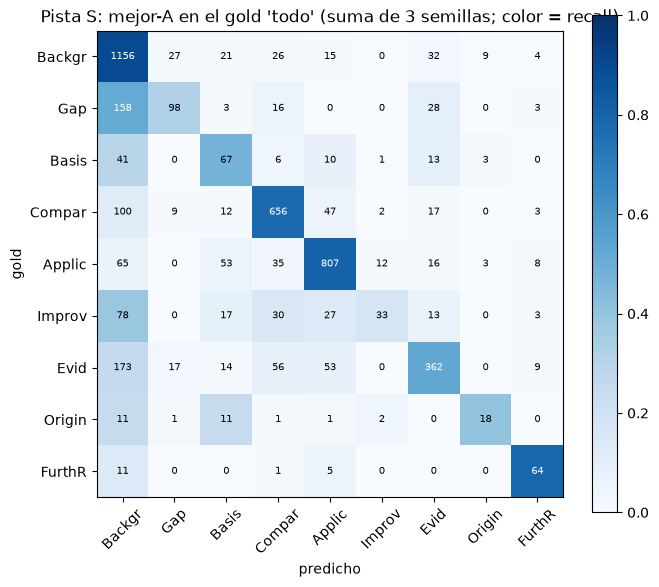

In [32]:
# ---------------------------------------------------------------- F1 por clase con IC95 (bootstrap por citante) y confusion
def f1_clase_ic(nombre: str, sub: str) -> pd.DataFrame:
    ids_m = sorted(SUBS[sub])
    y = [ETIQ[c] for c in ids_m]
    preds = [[MODELOS[nombre][s][c] for c in ids_m] for s in SEMILLAS]
    obs = metrica_observada(y, preds).mean(0)
    boot = metricas_bootstrap(y, preds, [CTX[c]["citing_id"] for c in ids_m]).mean(1)
    return pd.DataFrame({"modelo": nombre, "subconjunto": sub, "clase": CLASES, "soporte": np.bincount(y, minlength=N_CLASES),
                         "f1": obs, "ic95_inf": np.quantile(boot, 0.025, axis=0), "ic95_sup": np.quantile(boot, 0.975, axis=0)})


F1_CLASE = pd.concat([f1_clase_ic("mejor-A", "todo"), f1_clase_ic("E0-A", "todo"), f1_clase_ic("ref-104", "todo"),
                      f1_clase_ic("mejor-A", "todo_cob"), f1_clase_ic("mejor-AB", "todo_cob")], ignore_index=True)
F1_CLASE.to_csv(EVIDENCIAS / f"{PISTA}_gold_f1_por_clase.csv", index=False)
print(F1_CLASE.pivot_table(index="clase", columns=["modelo", "subconjunto"], values="f1", sort=False).reindex(CLASES).round(3).to_string())

ids_todo = sorted(SUBS["todo"])
CONF = sum(matriz_confusion([ETIQ[c] for c in ids_todo], [MODELOS["mejor-A"][s][c] for c in ids_todo]) for s in SEMILLAS)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(CONF / CONF.sum(1, keepdims=True).clip(min=1), cmap="Blues", vmin=0, vmax=1)
for i in range(N_CLASES):
    for j in range(N_CLASES):
        ax.text(j, i, CONF[i, j], ha="center", va="center", fontsize=7, color="white" if CONF[i, j] > CONF.sum(1)[i] * 0.5 else "black")
ax.set_xticks(range(N_CLASES), CORTAS, rotation=45)
ax.set_yticks(range(N_CLASES), CORTAS)
ax.set_xlabel("predicho")
ax.set_ylabel("gold")
ax.set_title(f"Pista {PISTA}: mejor-A en el gold 'todo' (suma de {len(SEMILLAS)} semillas; color = recall)")
plt.colorbar(im)
plt.tight_layout()
plt.show()

In [33]:
# ---------------------------------------------------------------- contrastes
CONTRASTES = [("AB - A", "mejor-AB", "mejor-A", "_cob"), ("mejor - E0", "mejor-A", "E0-A", ""),
              ("mejor-A - ref104", "mejor-A", "ref-104", "")]
FILAS_C = []
for base in ("todo", "humano", "concordancia"):
    resultados = {}
    for etiqueta, x, a, sufijo in CONTRASTES:
        ids_m = sorted(SUBS[base + sufijo])
        if not ids_m:
            continue
        r = prueba_combinada([[MODELOS[x][s][c] for c in ids_m] for s in SEMILLAS], [[MODELOS[a][s][c] for c in ids_m] for s in SEMILLAS],
                             [ETIQ[c] for c in ids_m], [CTX[c]["citing_id"] for c in ids_m])
        resultados[etiqueta] = {"subconjunto": base + sufijo, "contraste": etiqueta, **r}
    p_holm = holm({k: v["p"] for k, v in resultados.items()})
    p_tost_holm = holm({k: v["p_tost"] for k, v in resultados.items()})
    for k, v in resultados.items():
        FILAS_C.append({**v, "p_holm": p_holm[k], "p_tost_holm": p_tost_holm[k],
                        "decision": ("mejora" if v["diferencia"] > 0 else "empeora") if p_holm[k] < ALFA
                        else ("equivalente (±δ)" if p_tost_holm[k] < ALFA else "no concluyente")})
TABLA_CONTRASTES = pd.DataFrame(FILAS_C)
TABLA_CONTRASTES.drop(columns="diferencia_por_semilla").to_csv(EVIDENCIAS / f"{PISTA}_gold_contrastes.csv", index=False)
print(TABLA_CONTRASTES[["subconjunto", "contraste", "diferencia", "ic95_inf", "ic95_sup", "se", "gl", "p", "p_holm", "p_tost_holm", "decision"]]
      .round(4).to_string(index=False))

     subconjunto        contraste  diferencia  ic95_inf  ic95_sup     se        gl      p  p_holm  p_tost_holm       decision
        todo_cob           AB - A      0.0139   -0.0087    0.0364 0.0096    7.2495 0.1915  0.4817       0.5424 no concluyente
            todo       mejor - E0     -0.0051   -0.0330    0.0228 0.0117    6.6392 0.6769  0.6769       0.3654 no concluyente
            todo mejor-A - ref104     -0.0150   -0.0365    0.0065 0.0103   20.3546 0.1606  0.4817       0.5424 no concluyente
      humano_cob           AB - A      0.0136   -0.0158    0.0431 0.0127    7.8119 0.3167  0.6334       0.6288 no concluyente
          humano       mejor - E0     -0.0023   -0.0256    0.0210 0.0112   21.6247 0.8377  0.8377       0.1953 no concluyente
          humano mejor-A - ref104     -0.0210   -0.0422    0.0003 0.0108 7540.6355 0.0531  0.1592       0.6288 no concluyente
concordancia_cob           AB - A     -0.0319   -0.0957    0.0320 0.0247    4.9112 0.2543  0.7630       1.0000 no conc

In [34]:
# ---------------------------------------------------------------- tabla final y conclusiones
TABLA_FINAL = (AGREGADO_GOLD.assign(f1_macro=lambda d: d.f1_macro_media.round(4).astype(str) + " ± " + d.f1_macro_de.round(4).astype(str),
                                    f1_weighted=lambda d: d.f1_weighted_media.round(4).astype(str) + " ± " + d.f1_weighted_de.round(4).astype(str),
                                    accuracy=lambda d: d.accuracy_media.round(4).astype(str) + " ± " + d.accuracy_de.round(4).astype(str))
               .pivot(index="modelo", columns="subconjunto", values="f1_macro"))
print("F1-macro (media ± DE entre semillas) por subconjunto:")
print(TABLA_FINAL.to_string())
escribir_json(EVIDENCIAS / f"{PISTA}_resumen.json", {
    "pista": PISTA, "modo_prueba": MODO_PRUEBA, "gold_sha256": GOLD_SHA, "ganador_V": GANADOR, "semillas": SEMILLAS,
    "controles": TABLA_CONTROLES.to_dict(), "cobertura_gold": {"v1": COBERTURA_GOLD_V1["ok"], "v2": len(COB_GOLD), "n": len(GOLD_FILAS)},
    "paridad_top3": PARIDAD, "sha_ids": SHA_IDS, "n": {k: len(v) for k, v in CONJ.items()}, "entorno": ENTORNO})


def frase(fila: pd.Series) -> str:
    return (f"{fila.contraste} en {fila.subconjunto}: Δ F1-macro = {fila.diferencia:+.4f} "
            f"[IC95 {fila.ic95_inf:+.4f}; {fila.ic95_sup:+.4f}], p_Holm = {fila.p_holm:.3f} → {fila.decision}")


todo = TABLA_CONTRASTES[TABLA_CONTRASTES.subconjunto.str.startswith("todo")]
print(f"\nConclusiones (pista {PISTA}).")
print(f"La configuración elegida solo en V fue {EST} con lr {LR:g}, {'con' if PH else 'sin'} ajuste post-hoc de sesgos.")
print(f"En el gold completo:")
for _, f in todo.iterrows():
    print(" -", frase(f))
print("El mismo contraste en 'humano' y 'concordancia' está en la tabla de contrastes. Una decisión 'no concluyente' no equivale "
      "a evidencia de igualdad: para eso hace falta que el TOST (±0,02) sea significativo.")

F1-macro (media ± DE entre semillas) por subconjunto:
subconjunto     concordancia concordancia_cob           humano       humano_cob             todo         todo_cob
modelo                                                                                                           
E0-A         0.7336 ± 0.0373  0.7336 ± 0.0373   0.587 ± 0.0097  0.5867 ± 0.0097  0.5895 ± 0.0041  0.5893 ± 0.0041
mejor-A      0.7522 ± 0.0216  0.7522 ± 0.0216  0.5847 ± 0.0163  0.5844 ± 0.0163  0.5844 ± 0.0124  0.5842 ± 0.0124
mejor-AB     0.7203 ± 0.0142  0.7203 ± 0.0142              NaN   0.598 ± 0.0041              NaN  0.5981 ± 0.0057
ref-104      0.7278 ± 0.0421  0.7278 ± 0.0421  0.6057 ± 0.0178  0.6054 ± 0.0178  0.5995 ± 0.0096  0.5993 ± 0.0097

Conclusiones (pista S).
La configuración elegida solo en V fue E3 con lr 2e-05, sin ajuste post-hoc de sesgos.
En el gold completo:
 - AB - A en todo_cob: Δ F1-macro = +0.0139 [IC95 -0.0087; +0.0364], p_Holm = 0.482 → no concluyente
 - mejor - E0 en todo: Δ F1-